# Lab 2: Characterization and separability of real canine and murine ECG recordings

**Course:** Leveling in Biomedical Engineering Sciences

**Program:** Master in Biomedical Engineering, Institución Universitaria ITM

**Professor:** Sebastián Roldán Vasco

**Student:** Eliana Andrea Zuleta Cardona

**Date:** November 2026

# 1. Brief context

The electrocardiogram (ECG) is a fundamental tool in veterinary cardiology for the diagnosis of arrhythmias and conduction disorders in dogs (Santilli et al., 2018; Hellemans et al., 2022). Its interpretation requires experienced personnel, which has motivated the development of computational tools to support the analysis of the canine ECG (Dourson et al., 2023; Flanders et al., 2025).

In the human ECG, these tools have been developed from large sets of annotated recordings available in public databases (Moody & Mark, 2001; Wagner et al., 2020). In dogs, by contrast, the availability of recordings is considerably lower, which limits the development of equivalent tools for this species (Dourson et al., 2023; Breeding-Allison & Walleser, 2026). Given this scarcity, the generation of synthetic signals has been proposed as an alternative to expand ECG datasets (Monachino et al., 2023; Zanchi et al., 2025).

Both automated analysis and signal synthesis require first understanding the characteristics of real recordings. These characteristics vary among individuals of the same species according to factors such as breed, age, sex, and recording conditions (Mukherjee et al., 2020; Romito et al., 2022; Hertzer et al., 2022). Moreover, they differ considerably between species. Heart rate (HR) and wave durations change markedly among mammals, so analysis tools developed for one species cannot be directly applied to another (Behar et al., 2018). For this reason, the present lab analyzes real recordings from two species to examine how their ECG differs.

The data come from the PhysioZoo mammalian databases, openly available on PhysioNet (Behar et al., 2018; Shemla & Behar, 2019; Pollard et al., 2026). This work uses the dog and mouse databases. All recordings were acquired in conscious animals without prior drug administration, and each one includes R-peaks reviewed and manually corrected, as well as the identification of low-quality segments. The dog recordings were obtained with surface electrodes placed on both sides of the chest, whereas the mouse recordings were obtained with telemetry sensors. Table 1 summarizes the main characteristics of both databases.

**Table 1.** Characteristics of the PhysioZoo dog and mouse databases.

| Characteristic | Dog | Mouse |
|---|---|---|
| Recordings | 17, one per dog | 8, one per mouse |
| Rhythm | Sinus | Sinus |
| Acquisition | Surface electrodes on the chest | Telemetry sensors |
| Channels | 1 ECG channel (mV) | 1 ECG channel (mV) |
| Sampling frequency | 500 Hz | 1000 Hz |
| Duration per recording | 4 min 09 s to 6 min 48 s (mean 5 min 31 s) | 13 min 53 s to 39 min 38 s (mean 29 min 44 s) |
| Annotated R-peaks | 10,871 | 109,865 |
| Low-quality segments | 2.7% of total recording time | 0.4% of total recording time |

Since all recordings correspond to control animals in sinus rhythm, the databases do not include diagnostic classes. Therefore, classes are defined according to species. The mouse is a widely used animal model in cardiovascular research, and its HR is several times higher than that of the dog (Behar et al., 2018), which makes it possible to contrast two clearly different patterns of cardiac electrical activity. The PhysioZoo rabbit database was not included because its 20 recordings come from only four animals, which is insufficient to evaluate separability with independent animals.

# 2. Advanced data handling with Pandas

In this section, the dog and mouse recordings are loaded, cleaned, and organized so that they are ready for analysis. Each stage is accompanied by an explanation of what is done and why, and at the end a summary shows how much data was retained and excluded at each step.

## 2.1 Data loading, sampling frequency harmonization, and consistency verification

Each recording has up to three files: the ECG signal, the R-peaks and, when low-quality segments exist, a file with their beginning and end. Only dog and mouse files are loaded. The sampling frequency is read from the header of each file, which reveals a first inconsistency between databases: dogs were recorded at 500 Hz and mice at 1000 Hz. So that both species have windows with the same number of samples and comparable spectra, mouse signals are resampled to 500 Hz with a polyphase filter that prevents aliasing. R-peaks are converted to seconds with the original frequency of each file, so they remain valid after resampling.

Some mouse recordings contain short runs of missing samples. These runs are handled by removal: their location is stored and the windows containing them are excluded in Section 2.5. Since resampling and filtering require a continuous signal, the runs are temporarily bridged by linear interpolation, which, unlike a constant value, does not introduce jumps that the filter could spread into neighboring windows. These temporary values are never analyzed.

The data are organized into three tables (signal, beats, and low-quality segments) and each recording is summarized. Finally, data consistency is verified and the totals of each species are compared with those in Table 1.

In [96]:
# Install all packages used in this notebook (only installs what is missing)
%pip install -q numpy pandas matplotlib seaborn pyyaml scipy PyWavelets scikit-learn skrebate mrmr-selection

Note: you may need to restart the kernel to use updated packages.


In [97]:
from pathlib import Path
from abc import ABC, abstractmethod   # base classes for the OOP feature extractors (Section 3)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import yaml                           # reads the YAML headers of the PhysioZoo files
import pywt                           # wavelet transform (Section 3)
from scipy import stats                                           # statistical tests (Section 4)
from scipy.signal import welch, butter, sosfiltfilt, resample_poly  # spectrum, filtering, resampling

# Machine learning and feature selection tools (Sections 4 and 5)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from skrebate import ReliefF
from mrmr import mrmr_classif

# Relative path to the data folder (located next to the notebook)
DATA_DIR = Path("Data")
SPECIES = ["dog", "mouse"]       # species analyzed in this work
FS_TARGET = 500                  # common sampling frequency (Hz)
SPECIES_COLORS = {"dog": "tab:blue", "mouse": "tab:orange"}

In [98]:
def split_header(file_path):
    # Return the YAML header as a dictionary and the index of the first data line
    lines = Path(file_path).read_text().splitlines()
    # Header is enclosed between two '---' lines
    delimiters = [i for i, line in enumerate(lines) if line.strip() == "---"]
    if len(delimiters) < 2:
        raise ValueError(f"Header delimiters not found in {file_path}")
    header = yaml.safe_load("\n".join(lines[delimiters[0] + 1:delimiters[1]]))
    return header, delimiters[1] + 1


def read_physiozoo_series(file_path):
    # Read a PhysioZoo ECG or R-peak file: YAML header followed by one value per line
    header, first_data_line = split_header(file_path)
    values = pd.read_csv(file_path, skiprows=first_data_line, header=None, sep=r"\s+").iloc[:, 0]
    # Non-numeric entries become NaN so they can be counted later
    return header, pd.to_numeric(values, errors="coerce")


def read_quality_annotations(file_path):
    # Read a PhysioZoo quality file: table with Beginning, End (s) and Class
    _, first_data_line = split_header(file_path)
    table = pd.read_csv(file_path, skiprows=first_data_line, sep=r"\s+")
    # Clearer column names, including the unit
    return table.rename(columns={"Beginning": "begin_s", "End": "end_s", "Class": "quality_class"})

In [99]:
# Record identifiers taken from the ECG file names (only dog and mouse files)
record_ids = sorted(f.stem.replace("electrography_", "") for f in DATA_DIR.glob("electrography_*.txt")
                    if f.stem.split("_")[1].lower() in SPECIES)
print(f"Recordings found: {len(record_ids)}")

ecg_list, beat_list, quality_list, missing_list, summary_rows = [], [], [], [], []

for record_id in record_ids:
    # ECG signal and R-peak locations
    ecg_header, ecg_values = read_physiozoo_series(DATA_DIR / f"electrography_{record_id}.txt")
    peak_header, peak_values = read_physiozoo_series(DATA_DIR / f"peaks_{record_id}.txt")
    species = str(ecg_header["Mammal"]).lower()
    fs_ecg = float(ecg_header["Fs"])        # original sampling frequency of the ECG
    fs_peaks = float(peak_header["Fs"])     # sampling frequency used for the R-peak indices

    # Missing samples: store each continuous run (vectorized, no inner loop)
    missing_mask = ecg_values.isna().to_numpy()
    n_missing = int(missing_mask.sum())
    if n_missing > 0:
        edges = np.diff(np.r_[0, missing_mask.astype(int), 0])
        starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
        missing_list.append(pd.DataFrame({"record_id": record_id, "begin_s": starts / fs_ecg,
                                          "end_s": ends / fs_ecg, "n_samples": ends - starts}))
        # Temporary bridge so resampling and filtering do not spread NaN;
        # the windows containing these runs are removed in Section 2.5
        ecg_values = ecg_values.interpolate(limit_direction="both")

    # Harmonize the sampling frequency (polyphase resampling includes an anti-aliasing filter)
    ecg = ecg_values.to_numpy()
    if fs_ecg != FS_TARGET:
        ecg = resample_poly(ecg, up=FS_TARGET, down=int(fs_ecg))

    # Signal table: one row per sample (at FS_TARGET)
    ecg_list.append(pd.DataFrame({
        "record_id": record_id,
        "species": species,
        "sample": np.arange(len(ecg)),
        "time_s": np.arange(len(ecg)) / FS_TARGET,
        "ecg_mV": ecg,
    }))
    # Beat table: one row per R-peak, time computed with the original frequency
    beat_list.append(pd.DataFrame({
        "record_id": record_id,
        "species": species,
        "r_sample": peak_values.astype("Int64").to_numpy(),
        "r_time_s": peak_values.to_numpy() / fs_peaks,
    }))

    # Quality annotations (only available for some recordings)
    quality_file = DATA_DIR / f"Data_Quality_Annotations_{record_id}.txt"
    if quality_file.exists():
        quality = read_quality_annotations(quality_file)
        quality.insert(0, "record_id", record_id)
        quality_list.append(quality)
        n_bad_segments = len(quality)
        bad_time_s = (quality["end_s"] - quality["begin_s"]).sum()
    else:
        n_bad_segments, bad_time_s = 0, 0.0

    # Summary row for this recording
    summary_rows.append({
        "record_id": record_id,
        "species": species,
        "fs_ecg_Hz": fs_ecg,
        "fs_peaks_Hz": fs_peaks,
        "ecg_unit": ecg_header["Channels"][0]["unit"],
        "peak_unit": peak_header["Channels"][0]["unit"],
        "n_samples_original": len(ecg_values),
        "n_samples_500Hz": len(ecg),
        "duration_s": len(ecg_values) / fs_ecg,
        "missing_ecg_values": n_missing,
        "n_r_peaks": int(peak_values.notna().sum()),
        "quality_file": quality_file.exists(),
        "n_bad_segments": n_bad_segments,
        "bad_time_s": bad_time_s,
    })

# Join all recordings into single tables
ecg_long = pd.concat(ecg_list, ignore_index=True)
beats = pd.concat(beat_list, ignore_index=True)
quality_segments = pd.concat(quality_list, ignore_index=True)
missing_segments = (pd.concat(missing_list, ignore_index=True) if missing_list
                    else pd.DataFrame(columns=["record_id", "begin_s", "end_s", "n_samples"]))

# Categorical identifiers: less memory and a fixed order
for table in (ecg_long, beats, quality_segments, missing_segments):
    table["record_id"] = pd.Categorical(table["record_id"], categories=record_ids)
for table in (ecg_long, beats):
    table["species"] = pd.Categorical(table["species"], categories=SPECIES)

record_summary = pd.DataFrame(summary_rows).set_index("record_id")
record_summary["bad_time_pct"] = 100 * record_summary["bad_time_s"] / record_summary["duration_s"]
quality_segments["species"] = quality_segments["record_id"].map(record_summary["species"])
record_summary.round(2)

Recordings found: 25


,species,fs_ecg_Hz,fs_peaks_Hz,ecg_unit,peak_unit,n_samples_original,n_samples_500Hz,duration_s,missing_ecg_values,n_r_peaks,quality_file,n_bad_segments,bad_time_s,bad_time_pct
record_id,,,,,,,,,,,,,,
Dog_01,dog,500.0,500.0,mV,index,134258,134258,268.52,0,514,False,0,0.00,0.00
Dog_02,dog,500.0,500.0,mV,index,195703,195703,391.41,0,851,True,4,62.22,15.90
Dog_03,dog,500.0,500.0,mV,index,196888,196888,393.78,0,762,True,1,23.77,6.04
Dog_04,dog,500.0,500.0,mV,index,146086,146086,292.17,0,586,True,1,25.75,8.81
Dog_05,dog,500.0,500.0,mV,index,177092,177092,354.18,0,636,False,0,0.00,0.00
Dog_06,dog,500.0,500.0,mV,index,167636,167636,335.27,0,752,False,0,0.00,0.00
Dog_07,dog,500.0,500.0,mV,index,138526,138526,277.05,0,456,False,0,0.00,0.00
Dog_08,dog,500.0,500.0,mV,index,174945,174945,349.89,0,849,False,0,0.00,0.00
Dog_09,dog,500.0,500.0,mV,index,180449,180449,360.90,0,808,False,0,0.00,0.00


In [100]:
# Reference values per row, needed to compare peaks and segments against each recording
duration_per_beat = beats["record_id"].map(record_summary["duration_s"]).astype(float)
duration_per_segment = quality_segments["record_id"].map(record_summary["duration_s"]).astype(float)

# Each check returns True (passed) or False (inconsistency found)
checks = pd.DataFrame([
    ("ECG and R-peak files share the sampling frequency in every recording",
     (record_summary["fs_ecg_Hz"] == record_summary["fs_peaks_Hz"]).all()),
    ("Same sampling frequency within each species",
     (record_summary.groupby("species")["fs_ecg_Hz"].nunique() == 1).all()),
    ("All signals resampled to the common frequency",
     np.allclose(record_summary["n_samples_500Hz"] / record_summary["duration_s"], FS_TARGET, rtol=1e-3)),
    ("ECG unit is mV in all records", (record_summary["ecg_unit"] == "mV").all()),
    ("R-peak locations given as sample index", (record_summary["peak_unit"] == "index").all()),
    ("No missing ECG values in the original files", record_summary["missing_ecg_values"].sum() == 0),
    ("No missing values remain after bridging", ecg_long["ecg_mV"].notna().all()),
    ("R-peaks strictly increasing in every record",
     beats.groupby("record_id", observed=True)["r_time_s"]
          .apply(lambda s: s.is_monotonic_increasing and s.is_unique).all()),
    ("All R-peaks inside the ECG signal", (beats["r_time_s"] < duration_per_beat).all()),
    ("Quality segments inside the recording", (quality_segments["end_s"] <= duration_per_segment).all()),
], columns=["check", "passed"])
display(checks)


def to_hms(seconds):
    # Format a duration in seconds as h:min:s
    hours, remainder = divmod(int(round(seconds)), 3600)
    minutes, secs = divmod(remainder, 60)
    return f"{hours}:{minutes:02d}:{secs:02d}"


# Totals per species, to compare with Table 1
species_totals = record_summary.groupby("species").agg(
    recordings=("duration_s", "size"),
    sampling_frequency_Hz=("fs_ecg_Hz", "first"),
    total_duration_s=("duration_s", "sum"),
    total_r_peaks=("n_r_peaks", "sum"),
    low_quality_s=("bad_time_s", "sum"),
)
species_totals["low_quality_pct"] = (100 * species_totals["low_quality_s"]
                                     / species_totals["total_duration_s"]).round(2)
species_totals["total_duration"] = species_totals["total_duration_s"].apply(to_hms)
display(species_totals[["recordings", "sampling_frequency_Hz", "total_duration",
                        "total_r_peaks", "low_quality_pct"]])

# Runs of missing samples per recording
display(missing_segments.groupby("record_id", observed=True)
        .agg(runs=("n_samples", "size"), missing_samples=("n_samples", "sum"),
             first_s=("begin_s", "min"), last_s=("end_s", "max")))

,check,passed
0,ECG and R-peak files share the sampling freque...,True
1,Same sampling frequency within each species,True
2,All signals resampled to the common frequency,True
3,ECG unit is mV in all records,True
4,R-peak locations given as sample index,True
5,No missing ECG values in the original files,False
6,No missing values remain after bridging,True
7,R-peaks strictly increasing in every record,True
8,All R-peaks inside the ECG signal,True
9,Quality segments inside the recording,True


,recordings,sampling_frequency_Hz,total_duration,total_r_peaks,low_quality_pct
species,,,,,
dog,17,500.0,1:33:55,10860,2.69
mouse,8,1000.0,3:28:07,109865,0.37


,runs,missing_samples,first_s,last_s
record_id,,,,
Mouse_02,1,3,466.412,466.415
Mouse_05,2,91,1122.324,1307.979
Mouse_07,5,1873,78.263,728.975


**Interpretation of the results**

A total of 25 recordings were loaded, 17 from dogs and 8 from mice. The sampling frequency was consistent within each species (500 Hz in dogs and 1000 Hz in mice), and after resampling all signals were at 500 Hz. The total duration and the percentage of low-quality time agree with Table 1 for both species, as does the number of R-peaks in mice (109,865). In dogs, 10,860 peaks were obtained, 11 fewer than reported (0.1%). Since the cause cannot be determined from the files, the peaks contained in them were adopted as the reference.

The only check not passed concerns missing data. Mouse_02, Mouse_05, and Mouse_07 contain short runs without samples, which add up to less than 2 s in total. In Mouse_07, three of these runs coincide with annotated low-quality segments, indicating that they correspond to stretches where the recording was already affected. These runs are removed in Section 2.5. Finally, mouse recordings are much longer than dog recordings, so this species contributes more than twice as much recording time, an imbalance that is corrected in Section 2.6.

## 2.2 Data structuring: beat table

From the R-peaks, the RR interval (the time elapsed since the previous beat) and the instantaneous HR (60/RR, in beats per minute) are computed for each beat. The RR interval is computed within each recording, so that the last beat of one recording is not subtracted from the first beat of the next. For this reason, the first beat of each recording has no RR interval (NaN). Then, the RR intervals of each recording are summarized and the HR over time is plotted, with low-quality segments shaded. This review makes it possible to detect values that do not appear physiological, which are addressed in Section 2.3.

In [101]:
# RR interval computed within each recording (the first beat has no RR -> NaN)
beats["rr_s"] = beats.groupby("record_id", observed=True)["r_time_s"].diff()

# Instantaneous heart rate (bpm)
beats["hr_bpm"] = 60 / beats["rr_s"]

beats.head()

,record_id,species,r_sample,r_time_s,rr_s,hr_bpm
0,Dog_01,dog,189,0.378,NaN,NaN
1,Dog_01,dog,413,0.826,0.448,133.928571
2,Dog_01,dog,625,1.250,0.424,141.509434
3,Dog_01,dog,834,1.668,0.418,143.540670
4,Dog_01,dog,1064,2.128,0.460,130.434783


In [102]:
# Distribution of RR intervals per recording
rr_summary = beats.groupby("record_id", observed=True).agg(
    species=("species", "first"),
    n_beats=("r_time_s", "size"),
    missing_rr=("rr_s", lambda s: s.isna().sum()),
    rr_min_s=("rr_s", "min"),
    rr_median_s=("rr_s", "median"),
    rr_max_s=("rr_s", "max"),
    hr_median_bpm=("hr_bpm", "median"),
)
rr_summary.round(3)

,species,n_beats,missing_rr,rr_min_s,rr_median_s,rr_max_s,hr_median_bpm
record_id,,,,,,,
Dog_01,dog,514,1,0.332,0.494,0.940,121.457
Dog_02,dog,851,1,0.344,0.438,5.426,136.986
Dog_03,dog,762,1,0.364,0.492,11.186,121.951
Dog_04,dog,586,1,0.314,0.444,25.808,135.135
Dog_05,dog,636,1,0.450,0.552,0.726,108.696
Dog_06,dog,752,1,0.272,0.444,0.852,135.135
Dog_07,dog,456,1,0.412,0.586,0.992,102.389
Dog_08,dog,849,1,0.284,0.418,0.548,143.541
Dog_09,dog,808,1,0.316,0.448,0.642,133.929


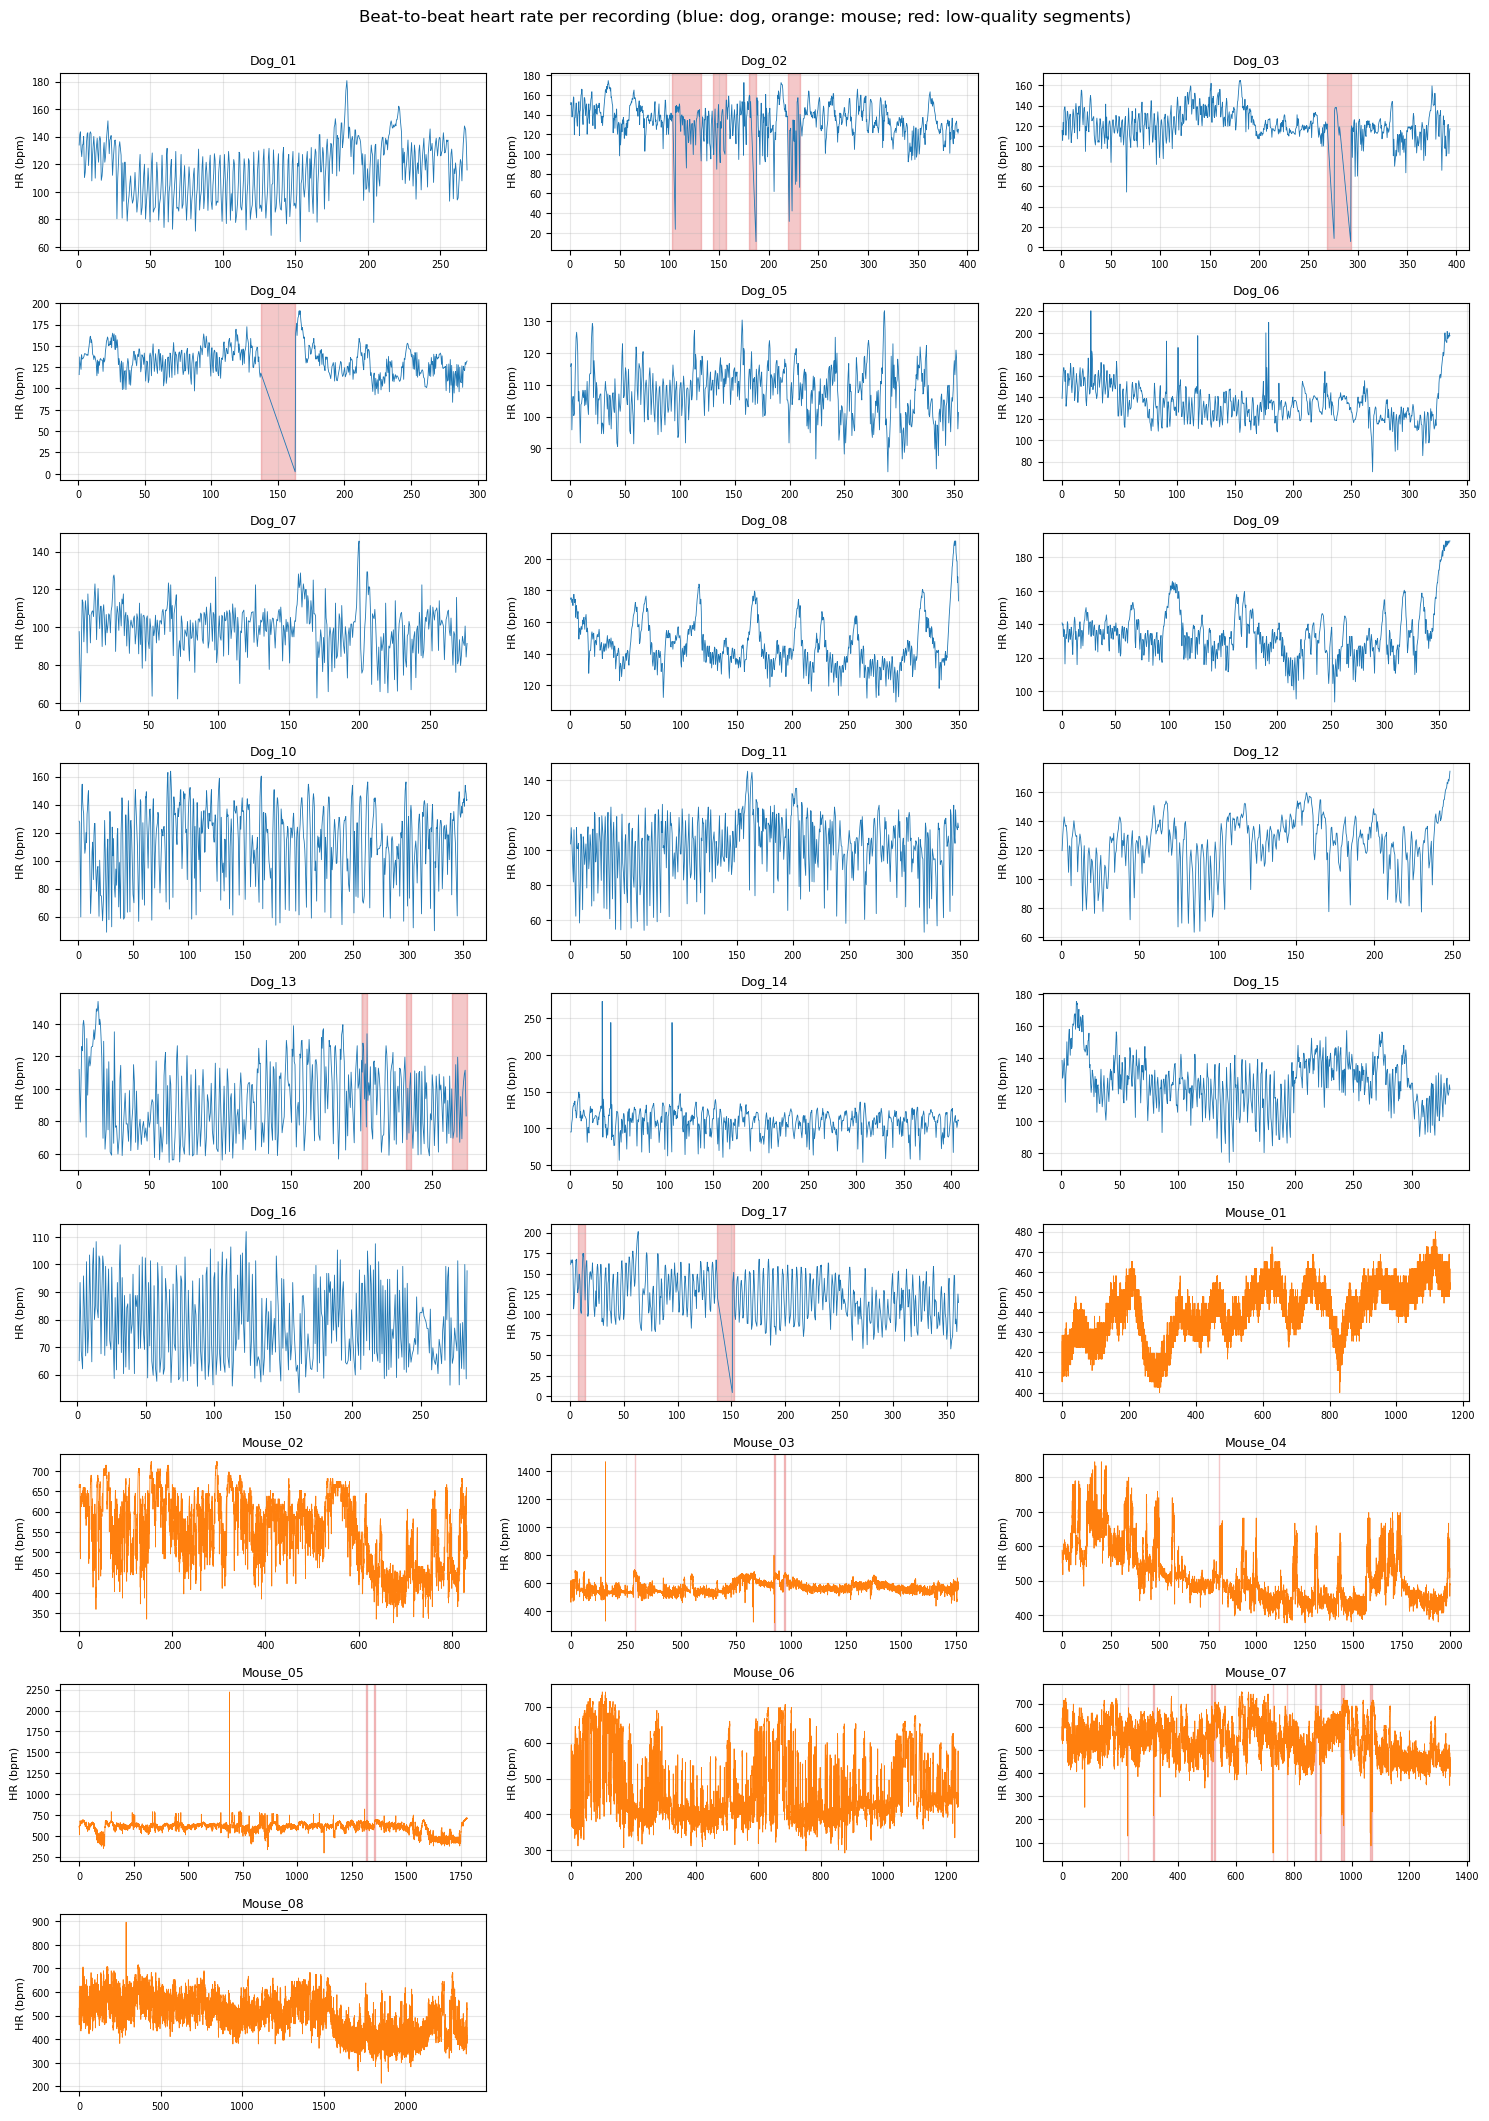

In [103]:
# Instantaneous HR over time for each recording; low-quality segments shaded in red
n_cols = 3
n_rows = int(np.ceil(len(record_ids) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 2.4 * n_rows))
axes = axes.ravel()

for ax, record_id in zip(axes, record_ids):
    rec = beats[beats["record_id"] == record_id]
    species = record_summary.loc[record_id, "species"]
    ax.plot(rec["r_time_s"], rec["hr_bpm"], color=SPECIES_COLORS[species], linewidth=0.6)
    for seg in quality_segments[quality_segments["record_id"] == record_id].itertuples():
        ax.axvspan(seg.begin_s, seg.end_s, color="tab:red", alpha=0.25)
    ax.set_title(record_id, fontsize=9)
    ax.set_ylabel("HR (bpm)", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3)

for ax in axes[len(record_ids):]:
    ax.axis("off")
fig.suptitle("Beat-to-beat heart rate per recording (blue: dog, orange: mouse; red: low-quality segments)",
             fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.98])   # leave space at the top for the title
plt.show()

**Interpretation of the results**

Each recording has a single missing RR interval, corresponding to its first beat, as expected. The median HR lies between 77 and 144 bpm in dogs and between 438 and 625 bpm in mice, that is, about four times higher in this species. The tachograms also show that, in several dogs (for example Dog_10, Dog_11, and Dog_16), HR rises and falls almost beat by beat. This pattern corresponds to respiratory sinus arrhythmia, a normal variation of HR associated with breathing in healthy dogs (Santilli et al., 2018), and is consistent with all recordings being from control animals.

The table and the figure also reveal extreme values that do not reflect the cardiac activity of the animal, but rather problems with the recording or its annotation. On the one hand, very long RR intervals appear within the shaded areas, as in Dog_04 (25.8 s) and Dog_17 (13.8 s), which are seen as drops in HR towards zero. These intervals correspond to stretches where the R-peaks were removed due to low quality. On the other hand, there are isolated, extremely fast beats, as in Dog_06, Dog_14, or Mouse_05, the latter with a minimum RR of 0.027 s, equivalent to more than 2000 bpm. These beats probably correspond to extra annotated R-peaks. Therefore, these values should not be interpreted as pathological findings, and they are addressed in Section 2.3.

## 2.3 Missing data, outliers, and low-quality segments

Each RR interval is evaluated with three criteria. Since the HR of the mouse is several times higher than that of the dog, thresholds are defined relative to each recording or species rather than as fixed values.

1. **Low quality:** the interval is flagged if it overlaps an annotated low-quality segment, evaluating the whole interval rather than only the position of the peak.
2. **Gaps:** intervals longer than three times the median RR of their recording are flagged. They correspond to stretches where the R-peaks were removed, so the interval joins two beats separated by an unannotated period. The factor of three was chosen from the data, since in recordings without quality problems the longest RR does not exceed about 2.5 times the median, even with marked sinus arrhythmia.
3. **Outlier beats:** an interval is flagged if its HR exceeds the 99th percentile of its species **and** it is shorter than 75% of the mean of its two neighbors. Both conditions are required because, separately, the first would flag normal and sustained HR increases, and the second would flag normal beats of sinus arrhythmia.

Flagged intervals are not filled, since inventing beats would alter the HR. Instead, they are converted into missing values (NaN) in new clean RR and HR columns, and the original values are kept for traceability. Finally, the number of intervals excluded by each criterion is summarized, and the original and clean HR are compared in representative recordings.

In [104]:
# Thresholds (justified in the Markdown cell above)
GAP_FACTOR = 3.0            # RR > 3 x median RR of the recording = gap in the annotations
OUTLIER_PERCENTILE = 99     # HR above this percentile of the species ...
NEIGHBOR_RATIO = 0.75       # ... and RR shorter than 75% of the mean of its two neighbors = outlier

# Start time of each RR interval (previous R-peak)
beats["rr_start_s"] = beats["r_time_s"] - beats["rr_s"]

# Criterion 1: RR interval overlapping an annotated low-quality segment
beats["in_bad_segment"] = False
for seg in quality_segments.itertuples():
    overlaps = ((beats["record_id"] == seg.record_id)
                & (beats["rr_start_s"] < seg.end_s)
                & (beats["r_time_s"] > seg.begin_s))
    beats.loc[overlaps, "in_bad_segment"] = True

# Criterion 2: gaps in the R-peak annotations (relative to the median RR of the recording)
median_rr = beats.groupby("record_id", observed=True)["rr_s"].transform("median")
beats["is_gap"] = beats["rr_s"] > GAP_FACTOR * median_rr

# Criterion 3: very fast AND isolated beat
hr_limit = beats.groupby("species", observed=True)["hr_bpm"].transform(
    lambda s: s.quantile(OUTLIER_PERCENTILE / 100))
print("99th percentile of instantaneous HR per species (bpm):")
print(beats.groupby("species", observed=True)["hr_bpm"].quantile(OUTLIER_PERCENTILE / 100).round(1).to_string())

rr_prev = beats.groupby("record_id", observed=True)["rr_s"].shift(1)
rr_next = beats.groupby("record_id", observed=True)["rr_s"].shift(-1)
neighbor_mean = (rr_prev + rr_next) / 2
beats["is_short_outlier"] = (beats["hr_bpm"] > hr_limit) & (beats["rr_s"] < NEIGHBOR_RATIO * neighbor_mean)

# Valid RR: not missing and not flagged by any criterion
beats["rr_valid"] = (beats["rr_s"].notna() & ~beats["in_bad_segment"]
                     & ~beats["is_gap"] & ~beats["is_short_outlier"])

# Clean columns: flagged values become NaN (original columns are kept)
beats["rr_clean_s"] = beats["rr_s"].where(beats["rr_valid"])
beats["hr_clean_bpm"] = beats["hr_bpm"].where(beats["rr_valid"])

99th percentile of instantaneous HR per species (bpm):
species
dog      178.6
mouse    705.9


In [105]:
# Number of RR intervals flagged by each criterion
# (an interval can meet more than one criterion, so columns do not necessarily add up)
flag_summary = beats.groupby("record_id", observed=True).agg(
    species=("species", "first"),
    n_rr=("rr_s", "count"),
    in_bad_segment=("in_bad_segment", "sum"),
    gaps=("is_gap", "sum"),
    short_outliers=("is_short_outlier", "sum"),
    valid_rr=("rr_valid", "sum"),
)
flag_summary["excluded_pct"] = 100 * (1 - flag_summary["valid_rr"] / flag_summary["n_rr"])

# Totals per species
species_flags = flag_summary.groupby("species", observed=True)[
    ["n_rr", "in_bad_segment", "gaps", "short_outliers", "valid_rr"]].sum()
species_flags["excluded_pct"] = 100 * (1 - species_flags["valid_rr"] / species_flags["n_rr"])

display(flag_summary.round(2))
display(species_flags.round(2))

,species,n_rr,in_bad_segment,gaps,short_outliers,valid_rr,excluded_pct
record_id,,,,,,,
Dog_01,dog,513,0,0,0,513,0.00
Dog_02,dog,850,115,4,0,735,13.53
Dog_03,dog,761,15,2,0,746,1.97
Dog_04,dog,585,2,1,0,583,0.34
Dog_05,dog,635,0,0,0,635,0.00
Dog_06,dog,751,0,0,6,745,0.80
Dog_07,dog,455,0,0,0,455,0.00
Dog_08,dog,848,0,0,0,848,0.00
Dog_09,dog,807,0,0,0,807,0.00


,n_rr,in_bad_segment,gaps,short_outliers,valid_rr,excluded_pct
species,,,,,,
dog,10843,181,8,9,10653,1.75
mouse,109857,457,6,6,109397,0.42


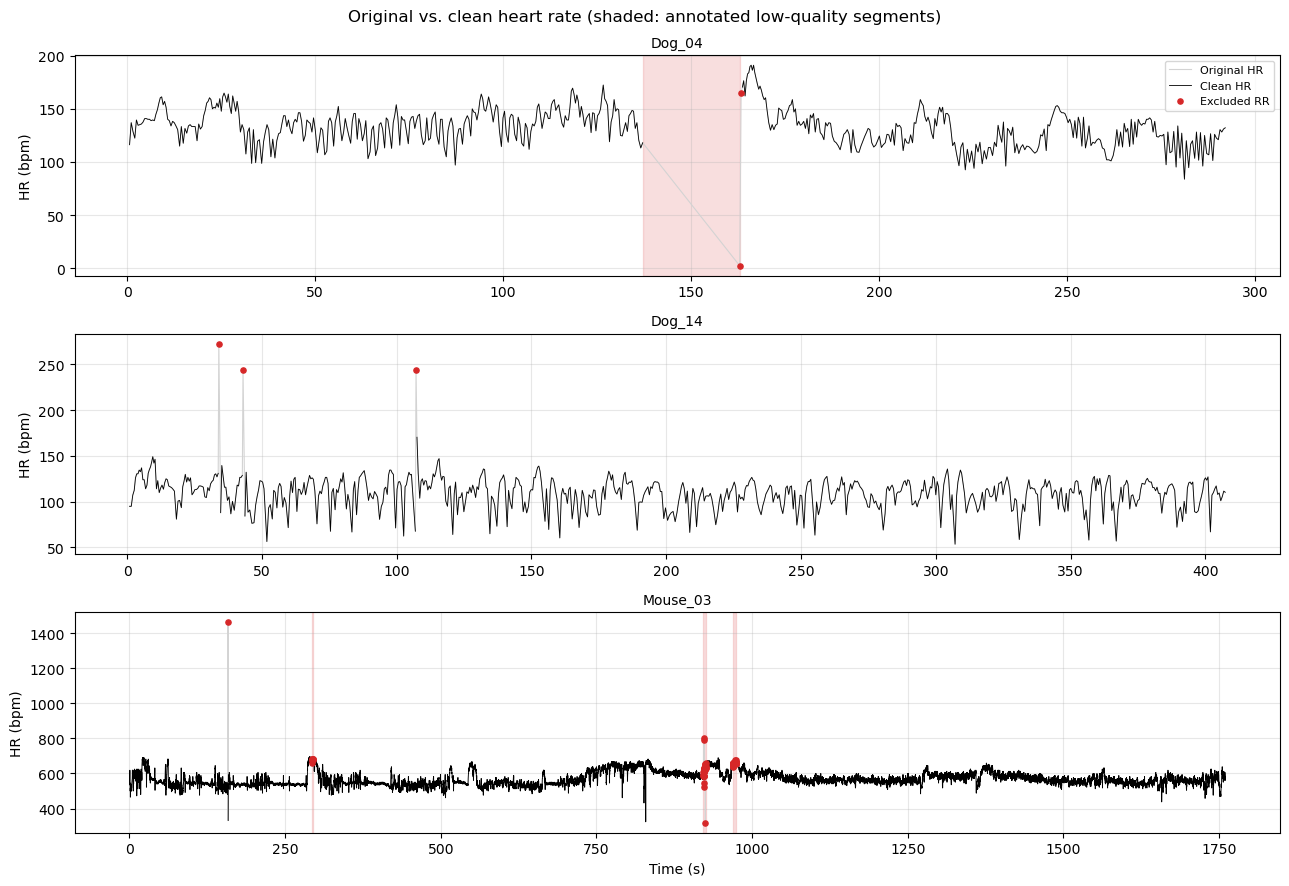

In [106]:
# Representative recordings: gap and outliers in dogs, outliers and low-quality segments in mice
candidates = ["Dog_04", "Dog_14", "Mouse_03"]
example_records = [r for r in candidates if r in record_ids]

fig, axes = plt.subplots(len(example_records), 1, figsize=(13, 3 * len(example_records)))
axes = np.atleast_1d(axes)
for ax, record_id in zip(axes, example_records):
    rec = beats[beats["record_id"] == record_id]
    ax.plot(rec["r_time_s"], rec["hr_bpm"], color="lightgray", linewidth=0.8, label="Original HR")
    ax.plot(rec["r_time_s"], rec["hr_clean_bpm"], color="black", linewidth=0.6, label="Clean HR")
    flagged = rec[~rec["rr_valid"] & rec["rr_s"].notna()]
    ax.scatter(flagged["r_time_s"], flagged["hr_bpm"], color="tab:red", s=14, zorder=3, label="Excluded RR")
    for seg in quality_segments[quality_segments["record_id"] == record_id].itertuples():
        ax.axvspan(seg.begin_s, seg.end_s, color="tab:red", alpha=0.15)
    ax.set_title(record_id, fontsize=10)
    ax.set_ylabel("HR (bpm)")
    ax.grid(alpha=0.3)

axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Original vs. clean heart rate (shaded: annotated low-quality segments)", fontsize=12)
fig.tight_layout()
plt.show()

**Interpretation of the results**

In dogs, 1.75% of the RR intervals were excluded (190 of 10,843), and in mice 0.42% (460 of 109,857). In both species, most exclusions correspond to intervals within low-quality segments, concentrated in a few recordings such as Dog_02 (13.5%), Dog_13 (6.8%), and Mouse_07 (2.5%). Gaps appeared only in recordings with annotated low-quality segments, indicating that the quality annotations and the R-peaks are consistent with each other. The 99th percentile of HR was 178.6 bpm in dogs and 705.9 bpm in mice, and with it 9 outlier beats were detected in dogs (Dog_06 and Dog_14) and 6 in mice.

The figure confirms that each criterion worked as expected. In Dog_04, the drop in HR towards zero caused by the gap disappears; in Dog_14, the three isolated peaks are removed; and in Mouse_03, an extra annotated beat near 158 s, equivalent to about 1460 bpm, is removed. In all cases, the physiological variability of the rest of the recording is preserved. It should be noted that the outlier criterion only searches for abnormally fast beats. Therefore, some isolated beats slower than usual, such as the one in Mouse_03 near 830 s, are retained, since they do not reach the gap threshold. Their effect on the mean HR of the window is minimal.

## 2.4 Signal filtering

Before extracting features, it is necessary to reduce the components that do not originate from cardiac activity, mainly baseline wander, power-line interference, and muscle noise. Since HR and QRS duration differ markedly between species, the ECG is also expected to occupy different frequency bands. For this reason, the filter is chosen from the data: the power spectral density of each recording is first computed with Welch's method, and the cutoff frequencies for each species are then defined from it.

In [107]:
# Frequency bands to inspect (Hz); 250 Hz is the Nyquist frequency at 500 Hz
bands = [(0, 0.5), (0.5, 40), (40, 100), (100, 200), (200, 250)]

psd_per_record = {}
band_rows = []
for record_id, group in ecg_long.groupby("record_id", observed=True):
    x = group["ecg_mV"].to_numpy()
    # Welch power spectral density (mean removed)
    freqs, psd = welch(x - x.mean(), fs=FS_TARGET, nperseg=4096)
    psd_per_record[record_id] = psd
    # Percentage of the total power contained in each band
    band_rows.append({"record_id": record_id, "species": record_summary.loc[record_id, "species"],
                      **{f"{lo}-{hi} Hz": 100 * psd[(freqs >= lo) & (freqs < hi)].sum() / psd.sum()
                         for lo, hi in bands}})

band_power = pd.DataFrame(band_rows).set_index("record_id")
display(band_power.round(2))
display(band_power.groupby("species").median(numeric_only=True).round(2))

,species,0-0.5 Hz,0.5-40 Hz,40-100 Hz,100-200 Hz,200-250 Hz
record_id,,,,,,
Dog_01,dog,4.95,94.33,0.72,0.00,0.00
Dog_02,dog,26.48,73.41,0.11,0.00,0.00
Dog_03,dog,10.91,88.96,0.13,0.00,0.00
Dog_04,dog,8.12,91.65,0.23,0.00,0.00
Dog_05,dog,1.15,98.79,0.07,0.00,0.00
Dog_06,dog,0.25,98.89,0.85,0.00,0.00
Dog_07,dog,0.25,98.98,0.77,0.00,0.00
Dog_08,dog,1.20,97.66,1.14,0.00,0.00
Dog_09,dog,1.28,97.60,1.12,0.00,0.00


,0-0.5 Hz,0.5-40 Hz,40-100 Hz,100-200 Hz,200-250 Hz
species,,,,,
dog,1.27,94.33,0.77,0.00,0.00
mouse,4.32,24.92,35.61,34.19,1.65


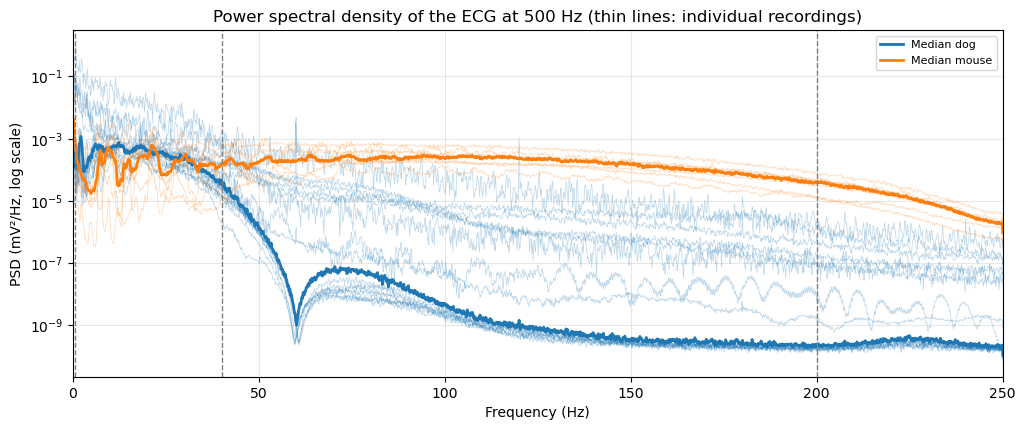

In [108]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for record_id, psd in psd_per_record.items():
    species = record_summary.loc[record_id, "species"]
    ax.semilogy(freqs, psd, color=SPECIES_COLORS[species], linewidth=0.5, alpha=0.3)
for species in SPECIES:
    ids = record_summary.index[record_summary["species"] == species]
    median_psd = np.median(np.vstack([psd_per_record[r] for r in ids]), axis=0)
    ax.semilogy(freqs, median_psd, color=SPECIES_COLORS[species], linewidth=2, label=f"Median {species}")

# Reference lines: candidate cutoff frequencies
for cutoff, style in [(0.5, "--"), (40, "--"), (200, "--")]:
    ax.axvline(cutoff, color="gray", linestyle=style, linewidth=1)
ax.set(xlim=(0, 250), xlabel="Frequency (Hz)", ylabel="PSD (mV²/Hz, log scale)",
       title="Power spectral density of the ECG at 500 Hz (thin lines: individual recordings)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

**Interpretation of the results**

The spectrum shows a clear difference between species. In dogs, 94% of the power is concentrated between 0.5 and 40 Hz, and above this value it drops sharply, with a notch at 60 Hz, which suggests filtering during acquisition. In mice, by contrast, about 70% of the power lies between 40 and 200 Hz, which is consistent with their higher HR and narrower QRS. In addition, Dog_02, Dog_13, and Mouse_07 show marked baseline wander, and Dog_10, Dog_12, Dog_16, and Dog_17 retain between 8% and 23% of their power above 40 Hz, probably due to muscle noise.

Therefore, a fourth-order, zero-phase Butterworth band-pass filter is applied with a band adapted to each species: 0.5–40 Hz in dogs and 0.5–200 Hz in mice. This reduces baseline wander and high-frequency noise without removing the cardiac activity of the mouse, which a common 40 Hz filter would have cut by about 70%. However, since the bandwidth differs between species, part of the spectral differences in the following sections will reflect this difference, in addition to physiology.

In [109]:
# Band-pass filter parameters per species (justified in the Markdown cell above)
FILTER_BANDS = {"dog": (0.5, 40.0), "mouse": (0.5, 200.0)}
FILTER_ORDER = 4


def bandpass(x, species):
    # Zero-phase Butterworth band-pass filter with the band of the given species
    low, high = FILTER_BANDS[species]
    sos = butter(FILTER_ORDER, [low, high], btype="bandpass", fs=FS_TARGET, output="sos")
    return sosfiltfilt(sos, x)


# Filtering applied to each recording separately, with the band of its species
ecg_long["ecg_filt_mV"] = ecg_long.groupby("record_id", observed=True)["ecg_mV"].transform(
    lambda s: bandpass(s.to_numpy(), record_summary.loc[s.name, "species"]))

ecg_long.head()

,record_id,species,sample,time_s,ecg_mV,ecg_filt_mV
0,Dog_01,dog,0,0.000,-0.006394,0.004214
1,Dog_01,dog,1,0.002,-0.003957,0.006360
2,Dog_01,dog,2,0.004,-0.001813,0.008547
3,Dog_01,dog,3,0.006,0.000000,0.010798
4,Dog_01,dog,4,0.008,0.002456,0.013109


,species,<0.5 Hz raw,>upper cutoff raw,<0.5 Hz filtered,>upper cutoff filtered
record_id,,,,,
Dog_01,dog,4.95,0.72,0.25,0.11
Dog_02,dog,26.48,0.11,3.92,0.02
Dog_03,dog,10.91,0.13,1.65,0.02
Dog_04,dog,8.12,0.23,1.28,0.03
Dog_05,dog,1.15,0.07,0.07,0.01
Dog_06,dog,0.25,0.85,0.03,0.13
Dog_07,dog,0.25,0.77,0.02,0.11
Dog_08,dog,1.20,1.15,0.17,0.17
Dog_09,dog,1.28,1.12,0.10,0.16


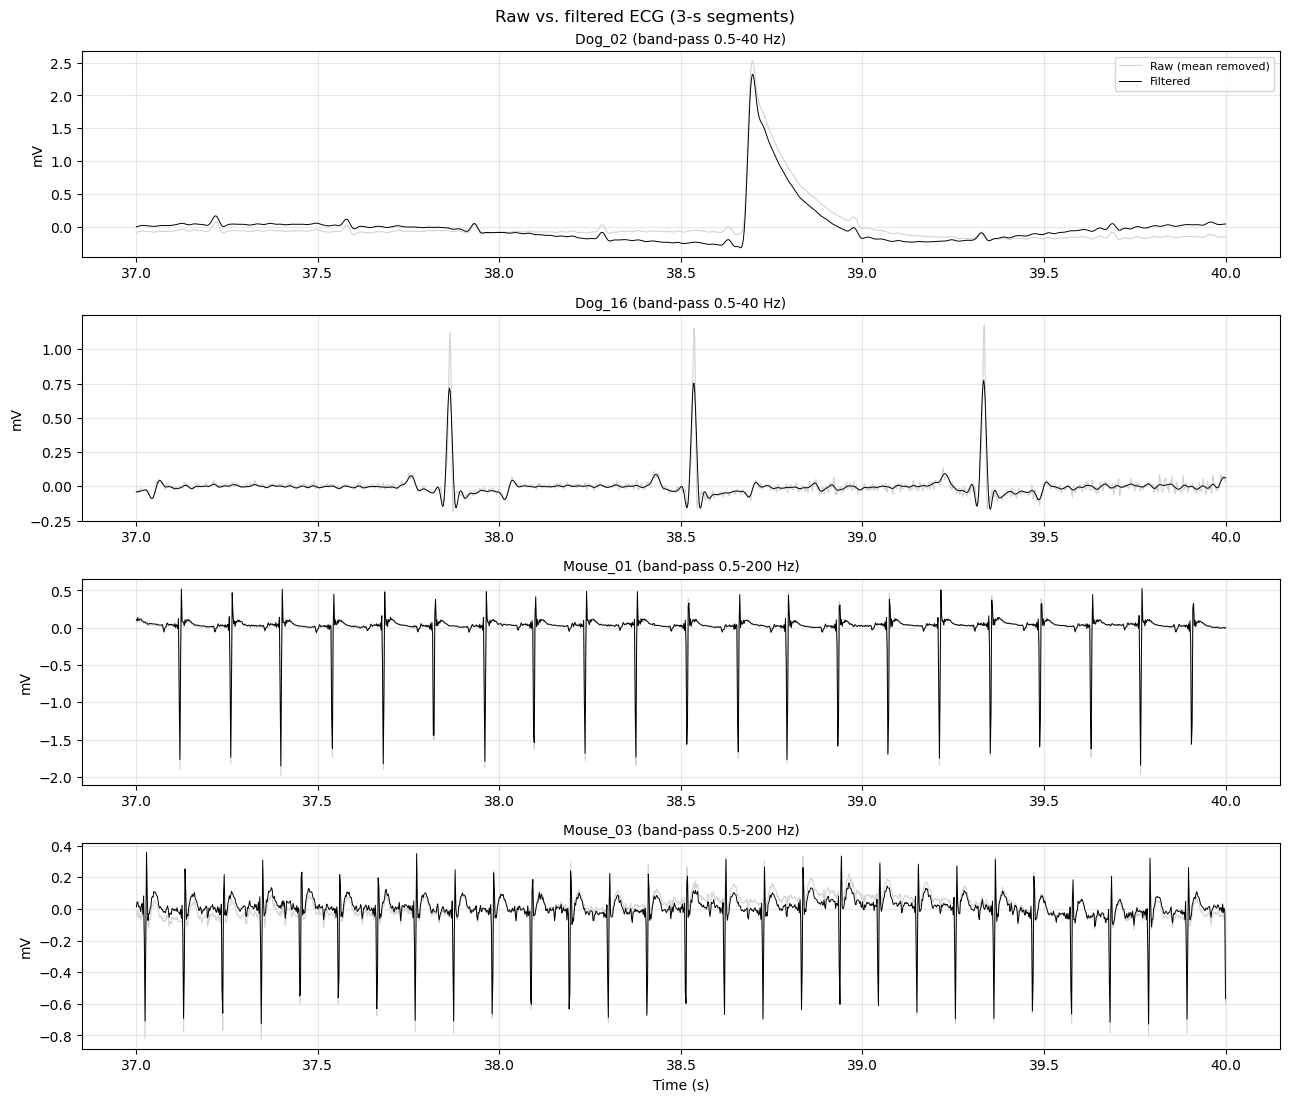

In [110]:
# Percentage of power below 0.5 Hz and above the upper cutoff, before and after filtering
check_rows = []
for record_id, group in ecg_long.groupby("record_id", observed=True):
    species = record_summary.loc[record_id, "species"]
    low, high = FILTER_BANDS[species]
    row = {"record_id": record_id, "species": species}
    for column, label in (("ecg_mV", "raw"), ("ecg_filt_mV", "filtered")):
        x = group[column].to_numpy()
        f, p = welch(x - x.mean(), fs=FS_TARGET, nperseg=4096)
        row[f"<{low} Hz {label}"] = 100 * p[f < low].sum() / p.sum()
        row[f">upper cutoff {label}"] = 100 * p[f > high].sum() / p.sum()
    check_rows.append(row)
filter_check = pd.DataFrame(check_rows).set_index("record_id")
display(filter_check.round(2))

# 3-s examples of both species
candidates = ["Dog_02", "Dog_16", "Mouse_01", "Mouse_03"]
example_records = [r for r in candidates if r in record_ids]
t_start, t_end = 37, 40

fig, axes = plt.subplots(len(example_records), 1, figsize=(13, 2.8 * len(example_records)))
axes = np.atleast_1d(axes)
for ax, record_id in zip(axes, example_records):
    d = ecg_long[(ecg_long["record_id"] == record_id) & ecg_long["time_s"].between(t_start, t_end)]
    ax.plot(d["time_s"], d["ecg_mV"] - d["ecg_mV"].mean(), color="lightgray", linewidth=0.8, label="Raw (mean removed)")
    ax.plot(d["time_s"], d["ecg_filt_mV"], color="black", linewidth=0.7, label="Filtered")
    low, high = FILTER_BANDS[record_summary.loc[record_id, "species"]]
    ax.set_title(f"{record_id} (band-pass {low}-{high:.0f} Hz)", fontsize=10)
    ax.set_ylabel("mV")
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Raw vs. filtered ECG (3-s segments)", fontsize=12)
fig.tight_layout()
plt.show()

**Interpretation of the results**

The filter considerably reduced the components it was intended to attenuate. The power below 0.5 Hz decreased in the recordings with the strongest baseline wander, for example from 26.5% to 3.9% in Dog_02 and from 36.9% to 2.0% in Mouse_07. The power above the upper cutoff remained below 1.6% in all recordings, even in the noisiest dogs such as Dog_16, which went from 23.3% to 1.5%. The remaining fraction is explained by the fact that the filter attenuates the frequencies close to the cutoffs progressively rather than abruptly.

The figure shows these effects on the signal. In mice, the filtered signal practically matches the original one, which confirms that the 0.5–200 Hz band preserves the QRS morphology. In these recordings, the R wave appears with negative polarity, which is taken into account when extracting features. In Dog_16, high-frequency noise is removed, but the R-wave amplitude is also reduced from about 1.15 to 0.75 mV, because its QRS retained components above 40 Hz that, in the other dogs, had already been removed during acquisition. Finally, in Dog_02 a large-amplitude artifact persists near 38.7 s, compatible with movement of the animal or of an electrode. The filter does not remove it because its frequency content overlaps with that of the cardiac signal, and it is handled with the amplitude check in Section 2.5.

## 2.5 Segmentation into 10-s windows

Each recording is divided into consecutive, non-overlapping 10-s windows, and the final stretch that does not complete 10 s is discarded. A window is excluded if it meets any of these conditions:

1. **Low quality:** it overlaps a low-quality segment, a gap in the R-peaks, or a run of missing samples, or it contains fewer than five valid RR intervals. The evaluation is time-based, so it is enough for part of the window to be affected.
2. **Outlier beat:** it contains any of the outlier beats detected in Section 2.3.
3. **Amplitude artifact:** its peak-to-peak amplitude exceeds twice the median of the windows of the same recording. The comparison is made within each recording because amplitude varies widely between animals and species. Flagged windows are inspected visually.

In valid windows, the mean HR is computed as 60 divided by the mean of the valid RR intervals.

In [111]:
WINDOW_S = 10.0
samples_per_window = int(WINDOW_S * FS_TARGET)   # 5000 samples per window

# One row per complete 10-s window of each recording (incomplete final stretch is discarded)
windows = pd.DataFrame([
    {"record_id": record_id, "species": record_summary.loc[record_id, "species"],
     "window": k, "t_start_s": k * WINDOW_S, "t_end_s": (k + 1) * WINDOW_S}
    for record_id in record_ids
    for k in range(int(record_summary.loc[record_id, "duration_s"] // WINDOW_S))
])
windows["record_id"] = pd.Categorical(windows["record_id"], categories=record_ids)
windows["species"] = pd.Categorical(windows["species"], categories=SPECIES)

discarded_s = (record_summary["duration_s"] % WINDOW_S).sum()
print(f"Windows created: {len(windows)} | Incomplete final stretches discarded: {discarded_s:.1f} s")
print(windows.groupby("species", observed=True).size().to_string())

Windows created: 1801 | Incomplete final stretches discarded: 112.4 s
species
dog       555
mouse    1246


In [112]:
MIN_VALID_RR = 5

# Remove columns from previous runs so the cell can be re-run safely
windows = windows.drop(columns=["n_valid_rr", "mean_rr_s", "hr_mean_bpm"], errors="ignore")

# Valid RR intervals and mean HR per window (beats assigned by the time of their R-peak)
beats["window"] = (beats["r_time_s"] // WINDOW_S).astype(int)
beat_stats = (beats.groupby(["record_id", "window"], observed=True)
              .agg(n_valid_rr=("rr_valid", "sum"), mean_rr_s=("rr_clean_s", "mean"))
              .reset_index())
windows = windows.merge(beat_stats, on=["record_id", "window"], how="left")
windows["n_valid_rr"] = windows["n_valid_rr"].fillna(0).astype(int)
windows["hr_mean_bpm"] = 60 / windows["mean_rr_s"]   # 60 / mean RR


def overlaps_any(intervals, start_col, end_col):
    # True for each window that overlaps in time with at least one of the given intervals
    flag = pd.Series(False, index=windows.index)
    for iv in intervals.itertuples():
        flag |= ((windows["record_id"] == iv.record_id)
                 & (windows["t_start_s"] < getattr(iv, end_col))
                 & (windows["t_end_s"] > getattr(iv, start_col)))
    return flag


# Time-based checks
windows["overlaps_bad_segment"] = overlaps_any(quality_segments, "begin_s", "end_s")
windows["overlaps_gap"] = overlaps_any(beats[beats["is_gap"]], "rr_start_s", "r_time_s")
windows["overlaps_missing"] = overlaps_any(missing_segments, "begin_s", "end_s")
windows["has_outlier_beat"] = overlaps_any(beats[beats["is_short_outlier"]], "rr_start_s", "r_time_s")

print("Windows overlapping missing samples:", int(windows["overlaps_missing"].sum()))

Windows overlapping missing samples: 8


In [113]:
AMPLITUDE_RATIO = 2.0   # window peak-to-peak > 2 x median of the same recording = artifact

# Remove columns from previous runs so the cell can be re-run safely
windows = windows.drop(columns=["ptp_mV", "ptp_ratio", "amplitude_artifact", "filter_edge",
                                "status", "is_valid"], errors="ignore")

# Peak-to-peak amplitude (max - min) of the filtered signal in each window
ecg_long["window"] = (ecg_long["time_s"] // WINDOW_S).astype(int)
ptp = (ecg_long.groupby(["record_id", "window"], observed=True)["ecg_filt_mV"]
       .agg(["max", "min"]).reset_index())
ptp["ptp_mV"] = ptp["max"] - ptp["min"]
windows = windows.merge(ptp[["record_id", "window", "ptp_mV"]], on=["record_id", "window"], how="left")

# Ratio to the median amplitude of the same recording
windows["ptp_ratio"] = windows["ptp_mV"] / windows.groupby("record_id", observed=True)["ptp_mV"].transform("median")
windows["amplitude_artifact"] = windows["ptp_ratio"] > AMPLITUDE_RATIO

# First and last window of each recording: affected by the edge effect of the filter
last_window = windows.groupby("record_id", observed=True)["window"].transform("max")
windows["filter_edge"] = (windows["window"] == 0) | (windows["window"] == last_window)

# Final status (the first condition that applies is assigned)
conditions = [
    windows["overlaps_bad_segment"] | windows["overlaps_gap"] | windows["overlaps_missing"]
    | (windows["n_valid_rr"] < MIN_VALID_RR),
    windows["filter_edge"],
    windows["has_outlier_beat"],
    windows["amplitude_artifact"],
]
windows["status"] = np.select(conditions, ["Low quality", "Filter edge", "Outlier beat", "Amplitude artifact"],
                              default="Valid")
windows["is_valid"] = windows["status"] == "Valid"

display(pd.crosstab([windows["species"], windows["record_id"]], windows["status"]))
display(pd.crosstab(windows["species"], windows["status"], margins=True, margins_name="Total"))

status             Amplitude artifact  Filter edge  Low quality  Outlier beat  \
species record_id                                                               
dog     Dog_01                      0            2            0             0   
        Dog_02                      1            2           11             0   
        Dog_03                      0            2            4             0   
        Dog_04                      0            2            4             0   
        Dog_05                      0            2            0             0   
        Dog_06                      0            2            0             5   
        Dog_07                      0            2            0             0   
        Dog_08                      0            2            0             0   
        Dog_09                      0            2            0             0   
        Dog_10                      0            2            0             0   
        Dog_11                      0            2            0             0   
        Dog_12                      0            2            0             0   
        Dog_13                      1            1            3             0   
        Dog_14                      0            2            0             3   
        Dog_15                      0            2            0             0   
        Dog_16                      0            2            0             0   
        Dog_17                      2            1            5             0   
mouse   Mouse_01                    0            2            0             0   
        Mouse_02                    0            2            1             0   
        Mouse_03                    0            2            4             1   
        Mouse_04                    0            2            1             0   
        Mouse_05                    0            2            4             1   
        Mouse_06                    0            2            0             0   
        Mouse_07                    1            2           14             0   
        Mouse_08                    0            2            0             1   

status             Valid  
species record_id         
dog     Dog_01        24  
        Dog_02        25  
        Dog_03        33  
        Dog_04        23  
        Dog_05        33  
        Dog_06        26  
        Dog_07        25  
        Dog_08        32  
        Dog_09        34  
        Dog_10        33  
        Dog_11        32  
        Dog_12        22  
        Dog_13        22  
        Dog_14        35  
        Dog_15        31  
        Dog_16        26  
        Dog_17        28  
mouse   Mouse_01     114  
        Mouse_02      80  
        Mouse_03     169  
        Mouse_04     196  
        Mouse_05     170  
        Mouse_06     122  
        Mouse_07     117  
        Mouse_08     234

status,Amplitude artifact,Filter edge,Low quality,Outlier beat,Valid,Total
species,,,,,,
dog,4,32,27,8,484,555
mouse,1,16,24,3,1202,1246
Total,5,48,51,11,1686,1801


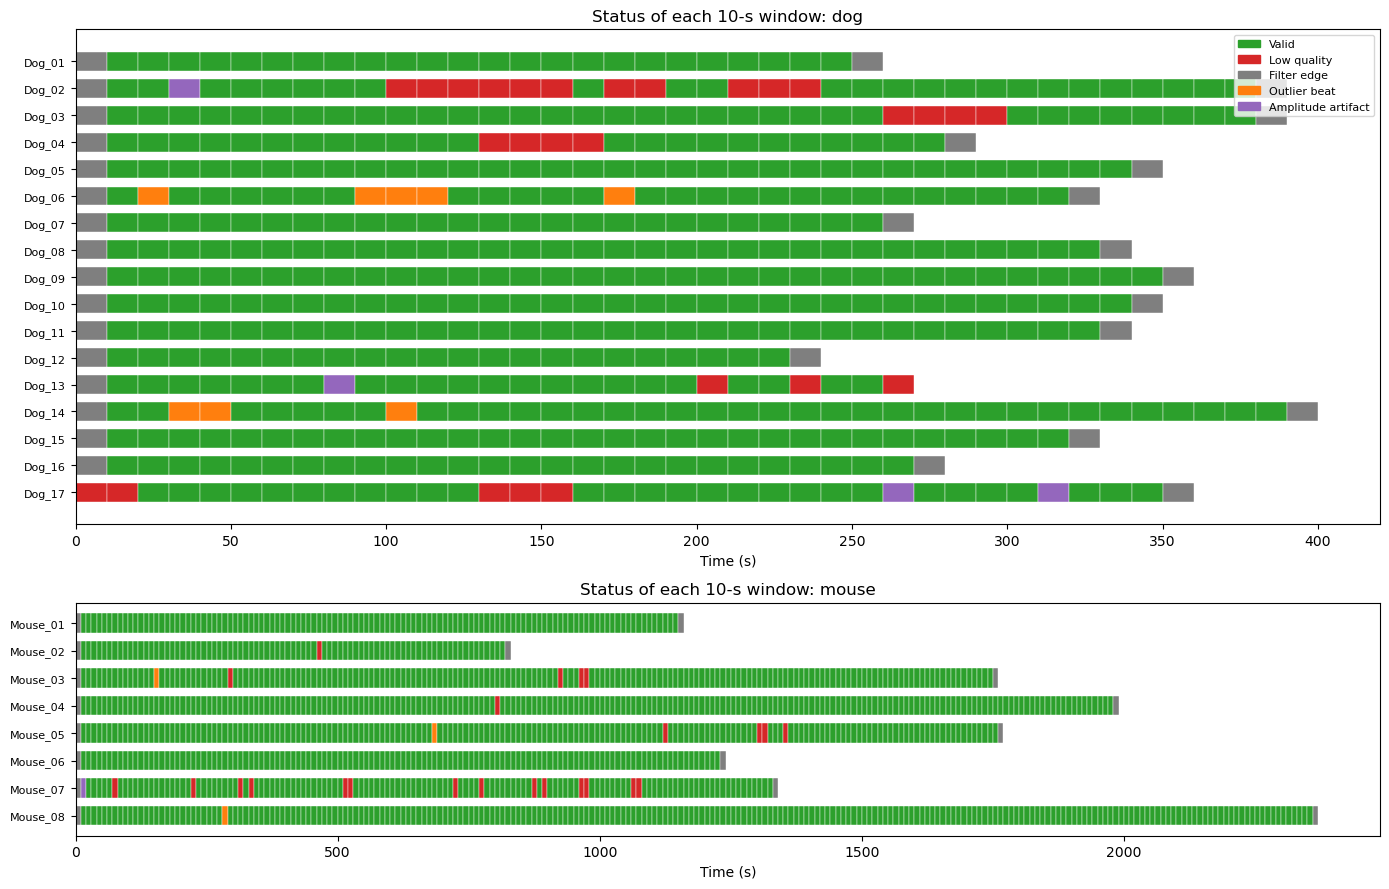

In [114]:
# Timeline of window status per recording, one panel per species (each with its own time axis)
status_colors = {"Valid": "tab:green", "Low quality": "tab:red", "Filter edge": "tab:gray",
                 "Outlier beat": "tab:orange", "Amplitude artifact": "tab:purple"}
ids_by_species = {sp: [r for r in record_ids if record_summary.loc[r, "species"] == sp] for sp in SPECIES}

fig, axes = plt.subplots(len(SPECIES), 1, figsize=(14, 9),
                         gridspec_kw={"height_ratios": [len(ids_by_species[sp]) for sp in SPECIES]})
for ax, species in zip(axes, SPECIES):
    for y, record_id in enumerate(ids_by_species[species]):
        d = windows[windows["record_id"] == record_id]
        ax.barh(y, width=WINDOW_S, left=d["t_start_s"], height=0.7,
                color=d["status"].map(status_colors), edgecolor="white", linewidth=0.3)
    ax.set_yticks(range(len(ids_by_species[species])), ids_by_species[species], fontsize=8)
    ax.invert_yaxis()
    ax.set(xlabel="Time (s)", title=f"Status of each 10-s window: {species}")

axes[0].legend(handles=[Patch(color=c, label=s) for s, c in status_colors.items()],
               loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

Windows flagged as amplitude artifacts: 5


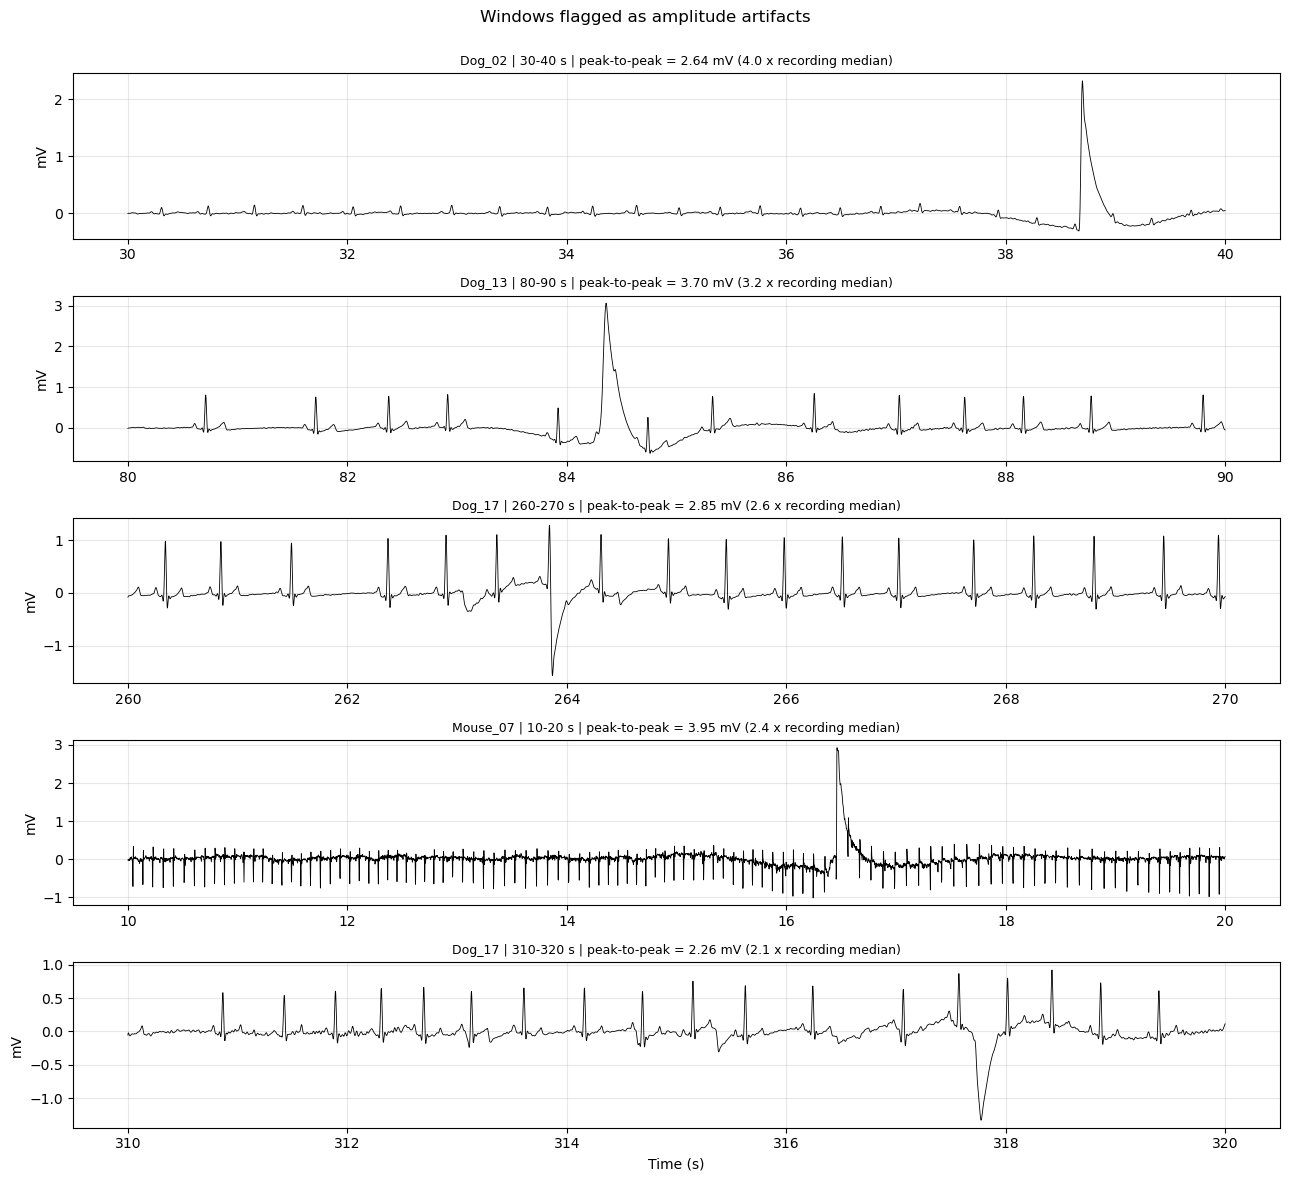

In [115]:
# Visual check of the windows flagged as amplitude artifacts (largest ratio first)
artifact_windows = (windows[windows["status"] == "Amplitude artifact"]
                    .sort_values("ptp_ratio", ascending=False).reset_index(drop=True))
print(f"Windows flagged as amplitude artifacts: {len(artifact_windows)}")

if len(artifact_windows) > 0:
    fig, axes = plt.subplots(len(artifact_windows), 1, figsize=(13, 2.4 * len(artifact_windows)))
    axes = np.atleast_1d(axes)
    for ax, row in zip(axes, artifact_windows.itertuples()):
        d = ecg_long[(ecg_long["record_id"] == row.record_id) & (ecg_long["window"] == row.window)]
        ax.plot(d["time_s"], d["ecg_filt_mV"], color="black", linewidth=0.6)
        ax.set_title(f"{row.record_id} | {row.t_start_s:.0f}-{row.t_end_s:.0f} s | "
                     f"peak-to-peak = {row.ptp_mV:.2f} mV ({row.ptp_ratio:.1f} x recording median)", fontsize=9)
        ax.set_ylabel("mV")
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle("Windows flagged as amplitude artifacts", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

**Interpretation of the results**

The segmentation produced 1801 windows of 10 s, 555 from dogs and 1246 from mice. A total of 484 dog windows (87.2%) and 1202 mouse windows (96.5%) were retained. In dogs, 71 windows were excluded: 27 due to low quality, 32 because they were at the edges of the recording, 8 due to outlier beats, and 4 due to amplitude artifacts. In mice, 44 were excluded: 24 due to low quality, 16 at the edges, 3 due to outlier beats, and 1 due to an artifact. The low-quality windows include the 8 windows that contained missing samples, in Mouse_02, Mouse_05, and Mouse_07. As the map shows, the remaining exclusions are concentrated in a few recordings, such as Dog_02 and Mouse_07. All dogs retain at least 22 valid windows and all mice at least 80.

The visual inspection confirms that the five windows flagged as artifacts do not correspond to cardiac activity. All of them show an abrupt, large-amplitude deflection followed by a slow return to baseline, while the surrounding QRS complexes remain unchanged. This pattern is compatible with movement of the animal or of an electrode. None of these windows was within the annotated low-quality segments, so they could only be detected with the amplitude check. One of them corresponds to the Dog_02 artifact identified in Section 2.4.

## 2.6 Class labels and balancing

Each valid window is labeled with its species of origin: dog (0) or mouse (1). Since mouse recordings are much longer, this class has more than twice as many valid windows. To prevent the larger class from dominating the statistical analysis and the classifier, the same number of windows is taken from each mouse until the total number of dog windows is matched. Windows are chosen evenly spaced along each recording rather than at random, so the selection is reproducible and covers the whole recording. All valid dog windows are kept. Finally, the signals of the selected windows are organized into a two-dimensional matrix (one row per window and one column per sample), which is the input for feature extraction.

In [116]:
valid_windows = windows[windows["is_valid"]].copy()
dog_windows = valid_windows[valid_windows["species"] == "dog"]
mouse_windows = valid_windows[valid_windows["species"] == "mouse"]

# Same number of windows from each mouse, so that both classes have a similar size
mouse_ids = mouse_windows["record_id"].unique()
n_per_mouse = int(np.ceil(len(dog_windows) / len(mouse_ids)))
print(f"Valid dog windows: {len(dog_windows)} | valid mouse windows: {len(mouse_windows)} "
      f"| windows selected per mouse: {n_per_mouse}")

selected_mouse = []
for record_id, rec in mouse_windows.groupby("record_id", observed=True):
    # Evenly spaced positions along the recording (reproducible, no random selection)
    positions = np.unique(np.linspace(0, len(rec) - 1, min(n_per_mouse, len(rec))).round().astype(int))
    selected_mouse.append(rec.iloc[positions])

dataset = pd.concat([dog_windows, *selected_mouse]).reset_index(drop=True)
dataset["label"] = (dataset["species"] == "mouse").astype(int)   # 0 = dog, 1 = mouse

# Number of animals and windows per class
class_summary = dataset.groupby("species", observed=True).agg(
    animals=("record_id", "nunique"), windows=("window", "size"),
    hr_mean_bpm=("hr_mean_bpm", "mean"))
class_summary.round(1)

Valid dog windows: 484 | valid mouse windows: 1202 | windows selected per mouse: 61


,animals,windows,hr_mean_bpm
species,,,
dog,17,484,116.0
mouse,8,488,525.0


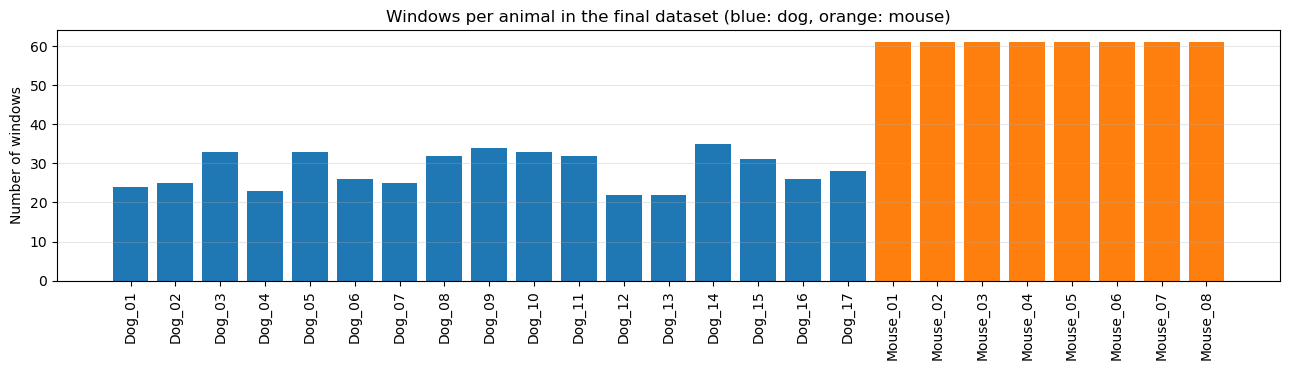

Signal matrix X_signals: 972 windows x 5000 samples


In [117]:
# Windows contributed by each animal to the final dataset
counts = dataset.groupby("record_id", observed=True).size()
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.bar(counts.index.astype(str), counts.values,
       color=[SPECIES_COLORS[record_summary.loc[r, "species"]] for r in counts.index])
ax.set(ylabel="Number of windows", title="Windows per animal in the final dataset (blue: dog, orange: mouse)")
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

# 2D signal matrix: one row per window of the final dataset, one column per sample
signals_by_record = {r: g["ecg_filt_mV"].to_numpy() for r, g in ecg_long.groupby("record_id", observed=True)}
X_signals = np.vstack([
    signals_by_record[row.record_id][row.window * samples_per_window:(row.window + 1) * samples_per_window]
    for row in dataset.itertuples()
])
print(f"Signal matrix X_signals: {X_signals.shape[0]} windows x {X_signals.shape[1]} samples")

**Interpretation of the results**

Of the 1202 valid mouse windows, 61 per animal were selected, for a total of 488 windows, compared with 484 dog windows. Both classes were thus left with practically the same size. The mean HR of the selected windows is 116.0 bpm in dogs and 525.0 bpm in mice, a difference of about 4.5 times between species. However, the figure shows that balance was achieved by class rather than by animal: each mouse contributes 61 windows, whereas each dog contributes between 22 and 35. Therefore, each mouse has a greater individual weight within its class, which is taken into account in Section 5 when validating the classifier by grouping windows by animal. The final signal matrix contains 972 windows of 5000 samples each.

## 2.7 Data handling summary

The following table summarizes, for each species, how much data was retained and excluded at each stage, from the R-peaks loaded to the final balanced dataset.

In [118]:
def count_by_species(mask_or_table, column="species"):
    # Count rows per species
    return mask_or_table.groupby(column, observed=True).size().reindex(SPECIES, fill_value=0)


steps = {
    "Recordings": record_summary.groupby("species").size().reindex(SPECIES),
    "R-peaks loaded": count_by_species(beats),
    "RR intervals": count_by_species(beats[beats["rr_s"].notna()]),
    "RR excluded: low-quality segment or gap": count_by_species(beats[beats["in_bad_segment"] | beats["is_gap"]]),
    "RR excluded: isolated outlier beat": count_by_species(
        beats[beats["is_short_outlier"] & ~beats["in_bad_segment"] & ~beats["is_gap"]]),
    "Valid RR intervals": count_by_species(beats[beats["rr_valid"]]),
    "10-s windows created": count_by_species(windows),
    **{f"Windows excluded: {s.lower()}": count_by_species(windows[windows["status"] == s])
        for s in ["Low quality", "Filter edge", "Outlier beat", "Amplitude artifact"]},
    "Valid windows": count_by_species(valid_windows),
    "Windows in the final balanced dataset": count_by_species(dataset),
}
trace = pd.DataFrame(steps).T
trace["Total"] = trace.sum(axis=1)
trace

species,dog,mouse,Total
Recordings,17,8,25
R-peaks loaded,10860,109865,120725
RR intervals,10843,109857,120700
RR excluded: low-quality segment or gap,181,457,638
RR excluded: isolated outlier beat,9,3,12
Valid RR intervals,10653,109397,120050
10-s windows created,555,1246,1801
Windows excluded: low quality,27,24,51
Windows excluded: filter edge,32,16,48
Windows excluded: outlier beat,8,3,11


**Interpretation of the results**

Data handling retained most of the original information. In dogs, 98.2% of the RR intervals were kept, and in mice 99.6%, as well as 87.2% and 96.5% of the windows, respectively. Exclusions were performed at two complementary levels. At the beat level, the intervals that distorted HR were removed, and at the window level, the stretches affected by low quality, missing data, filter edges, outlier beats, or artifacts were discarded. The final dataset consists of 972 windows balanced between species (484 from dogs and 488 from mice), which constitute the basis for feature extraction.

# 3. Feature extraction using OOP

Fourteen features organized in three domains are extracted from each window. A parent class, `FeatureExtractor`, defines a common structure: each extractor receives a window and returns its features. Three child classes inherit from it and define their own computation, and thanks to polymorphism they are all applied with the same method. Frequency and time-frequency features are computed only within the 0.5–40 Hz band, which both species retain after filtering, so that differences between species are not caused by the filter bandwidth. The ST segment is not included because, in the mouse, the T wave merges with the end of the QRS, which prevents measuring it comparably between species.

| Class | Domain | Feature | Description |
|---|---|---|---|
| `SpectralFeatures` | Frequency | MNF, MDF | Mean and median frequency of the spectrum; they indicate where the signal energy is concentrated, which shifts towards higher frequencies with faster rhythms and narrower QRS complexes |
| | | PKF | Peak frequency, the dominant component of the spectrum |
| | | MNP | Mean power, related to the overall amplitude of the signal |
| | | FR | Ratio between low-frequency (0.5–15 Hz) and high-frequency (15–40 Hz) power; it contrasts the slower waves (P and T) with the faster QRS components |
| `WaveletFeatures` | Time-frequency | E_A6, E_D6, E_D5, E_D4 | Relative energy of the db4 wavelet levels covering approximately 0–3.9, 3.9–7.8, 7.8–15.6, and 15.6–31.2 Hz; they describe how energy is distributed across scales while preserving time localization |
| `CardiacFeatures` | Cardiac (time) | HR | Mean heart rate of the window |
| | | SDNN, RMSSD | Overall and beat-to-beat RR variability, related to autonomic modulation such as respiratory sinus arrhythmia |
| | | R amplitude | Mean absolute R-wave amplitude (independent of polarity), related to the magnitude of ventricular depolarization |
| | | QRS width | Duration of the QRS at half amplitude, related to the duration of ventricular depolarization |

In [119]:
class FeatureExtractor(ABC):
    # Base class: every extractor receives one 10-s window and returns a dictionary of features

    domain = "generic"

    def __init__(self, fs):
        self.fs = fs

    @abstractmethod
    def extract(self, window, beats_in_window=None):
        # Return a dictionary {feature_name: value} for one window
        ...

    def extract_all(self, X, beat_groups=None):
        # Apply extract() to every row of the signal matrix and return a DataFrame
        rows = [self.extract(X[i], None if beat_groups is None else beat_groups[i]) for i in range(len(X))]
        return pd.DataFrame(rows)

In [120]:
class SpectralFeatures(FeatureExtractor):
    # Frequency-domain features computed from the Welch spectrum of the window

    domain = "frequency"

    def __init__(self, fs, band=(0.5, 40.0), low_band=(0.5, 15.0), high_band=(15.0, 40.0), nperseg=1000):
        super().__init__(fs)
        self.band, self.low_band, self.high_band, self.nperseg = band, low_band, high_band, nperseg

    def extract(self, window, beats_in_window=None):
        freqs, psd = welch(window - window.mean(), fs=self.fs, nperseg=self.nperseg)
        # Restrict to the band shared by both species after filtering
        in_band = (freqs >= self.band[0]) & (freqs <= self.band[1])
        f, p = freqs[in_band], psd[in_band]
        total = p.sum()
        low = p[(f >= self.low_band[0]) & (f < self.low_band[1])].sum()
        high = p[(f >= self.high_band[0]) & (f <= self.high_band[1])].sum()
        return {
            "MNF_Hz": (f * p).sum() / total,                         # mean frequency
            "MDF_Hz": f[np.searchsorted(np.cumsum(p), total / 2)],   # median frequency
            "PKF_Hz": f[np.argmax(p)],                               # peak frequency
            "MNP_mV2_Hz": p.mean(),                                  # mean power
            "FR": low / high,                                        # low/high frequency ratio
        }

In [121]:
class WaveletFeatures(FeatureExtractor):
    # Time-frequency features: relative energy of the discrete wavelet decomposition levels

    domain = "time-frequency"

    def __init__(self, fs, wavelet="db4", level=6, keep=("A6", "D6", "D5", "D4")):
        super().__init__(fs)
        self.wavelet, self.level, self.keep = wavelet, level, keep

    def extract(self, window, beats_in_window=None):
        coeffs = pywt.wavedec(window, self.wavelet, level=self.level)
        names = [f"A{self.level}"] + [f"D{k}" for k in range(self.level, 0, -1)]
        energy = {name: np.sum(c ** 2) for name, c in zip(names, coeffs)}
        # Relative energy among the levels inside the common band (about 0-31 Hz at 500 Hz)
        total = sum(energy[name] for name in self.keep)
        return {f"E_{name}": energy[name] / total for name in self.keep}

In [122]:
class CardiacFeatures(FeatureExtractor):
    # Cardiac features obtained from the R-peaks and the QRS complex of the window

    domain = "cardiac (time)"

    def __init__(self, fs, search_ms=6):
        super().__init__(fs)
        self.search = int(search_ms / 1000 * fs)   # samples searched around each annotated R-peak

    def _qrs(self, window, idx):
        # Absolute R amplitude (polarity-independent) and QRS width at half amplitude for one beat
        baseline = np.median(window)
        lo, hi = max(idx - self.search, 0), min(idx + self.search + 1, len(window))
        peak = lo + np.argmax(np.abs(window[lo:hi] - baseline))
        dev = np.abs(window - baseline)
        amplitude, half = dev[peak], dev[peak] / 2
        left, right = peak, peak
        while left > 0 and dev[left - 1] >= half:
            left -= 1
        while right < len(window) - 1 and dev[right + 1] >= half:
            right += 1
        return amplitude, (right - left + 1) / self.fs * 1000

    def extract(self, window, beats_in_window=None):
        rr = beats_in_window["rr_clean_s"].dropna().to_numpy()
        idx = beats_in_window["sample_in_window"].to_numpy()
        qrs = np.array([self._qrs(window, i) for i in idx])
        return {
            "HR_bpm": 60 / rr.mean(),                                      # mean heart rate
            "SDNN_ms": rr.std(ddof=1) * 1000,                              # overall RR variability
            "RMSSD_ms": np.sqrt(np.nanmean(np.diff(beats_in_window["rr_clean_s"].to_numpy()) ** 2)) * 1000,
            "R_amp_mV": qrs[:, 0].mean(),                                  # mean absolute R amplitude
            "QRS_width_ms": np.median(qrs[:, 1]),                          # QRS width at half amplitude
        }

In [123]:
# Beats of each window of the final dataset, with their position inside the window
beats["sample_in_window"] = ((beats["r_time_s"] - beats["window"] * WINDOW_S) * FS_TARGET).round().astype(int)
beats_by_window = {key: g for key, g in beats.groupby(["record_id", "window"], observed=True)}
beat_groups = [beats_by_window[(row.record_id, row.window)] for row in dataset.itertuples()]

# Extract the three feature groups with the same interface (polymorphism)
extractors = [SpectralFeatures(FS_TARGET), WaveletFeatures(FS_TARGET), CardiacFeatures(FS_TARGET)]
feature_tables = [extractor.extract_all(X_signals, beat_groups) for extractor in extractors]

features = pd.concat([dataset[["record_id", "species", "label"]].reset_index(drop=True), *feature_tables], axis=1)
feature_names = [c for table in feature_tables for c in table.columns]
feature_domain = {c: ext.domain for ext, table in zip(extractors, feature_tables) for c in table.columns}

print(f"Feature table: {features.shape[0]} windows x {len(feature_names)} features")
print("Missing values per feature:", int(features[feature_names].isna().sum().sum()))
features.head()

Feature table: 972 windows x 14 features
Missing values per feature: 0


,record_id,species,label,MNF_Hz,MDF_Hz,PKF_Hz,MNP_mV2_Hz,FR,E_A6,E_D6,E_D5,E_D4,HR_bpm,SDNN_ms,RMSSD_ms,R_amp_mV,QRS_width_ms
0,Dog_01,dog,0,15.441426,16.0,16.0,0.000132,0.816189,0.158301,0.088783,0.337966,0.414951,128.055879,38.948962,46.165334,0.348049,18.0
1,Dog_01,dog,0,9.027788,3.0,1.0,0.000250,2.379579,0.457439,0.073138,0.190998,0.278425,127.556185,73.249216,85.590887,0.348977,16.0
2,Dog_01,dog,0,16.513484,16.5,8.0,0.000129,0.727594,0.048238,0.138352,0.355260,0.458150,99.980396,79.389768,106.307337,0.420042,18.0
3,Dog_01,dog,0,16.522775,16.5,17.0,0.000120,0.725553,0.054875,0.137647,0.278614,0.528865,98.280098,94.045379,118.452241,0.415771,18.0
4,Dog_01,dog,0,16.555380,16.5,10.5,0.000123,0.727175,0.151204,0.148235,0.296966,0.403595,99.357101,100.345579,126.033726,0.425809,18.0


In [124]:
# Mean value of each feature per species (detailed statistics in Section 4)
features.groupby("species", observed=True)[feature_names].mean().T

species,dog,mouse
MNF_Hz,15.739712,18.685593
MDF_Hz,14.715909,18.723361
PKF_Hz,8.653926,11.845287
MNP_mV2_Hz,0.000275,0.000274
FR,1.028728,0.719982
E_A6,0.138172,0.176842
E_D6,0.134675,0.084327
E_D5,0.324523,0.270909
E_D4,0.402630,0.467922
HR_bpm,116.008973,525.014457


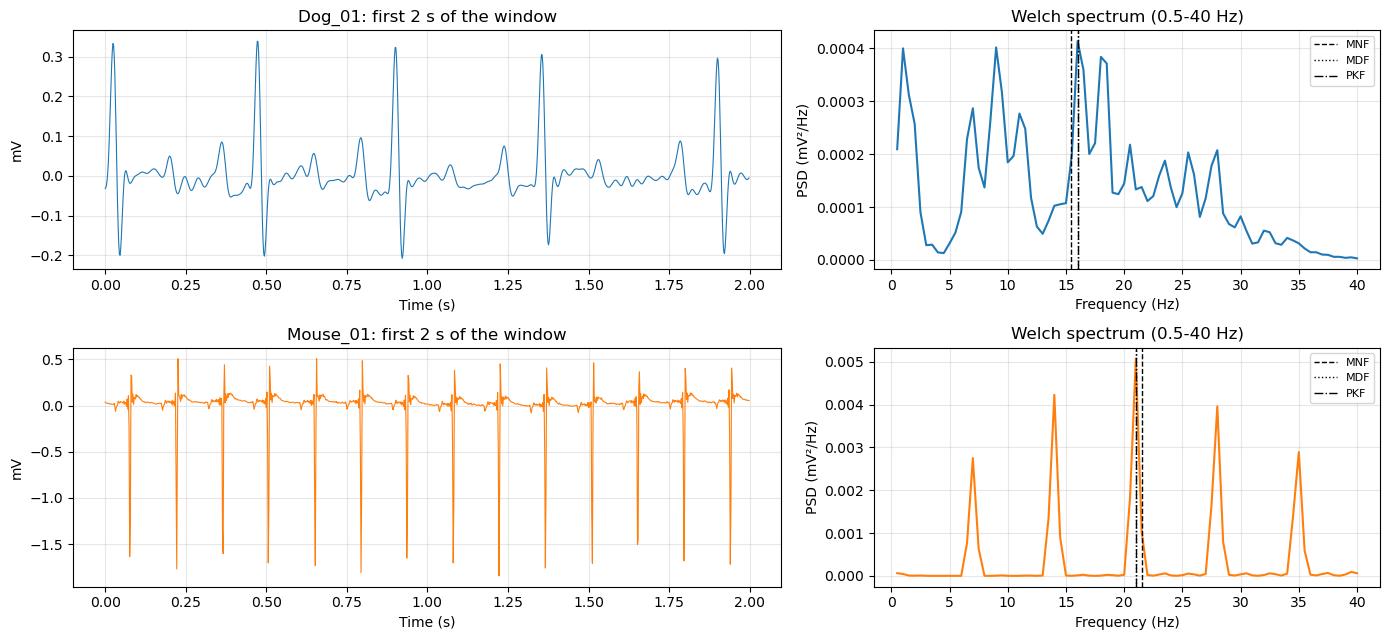

In [125]:
# Illustration of the frequency features on one window of each species
fig, axes = plt.subplots(2, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.4, 1]})
spectral = extractors[0]
for row_ax, species in zip(axes, SPECIES):
    i = features.index[features["species"] == species][0]
    x = X_signals[i]
    t = np.arange(len(x)) / FS_TARGET
    row_ax[0].plot(t[: 2 * FS_TARGET], x[: 2 * FS_TARGET], color=SPECIES_COLORS[species], linewidth=0.8)
    row_ax[0].set(title=f"{features.loc[i, 'record_id']}: first 2 s of the window", xlabel="Time (s)", ylabel="mV")
    f, p = welch(x - x.mean(), fs=FS_TARGET, nperseg=spectral.nperseg)
    band = (f >= 0.5) & (f <= 40)
    row_ax[1].plot(f[band], p[band], color=SPECIES_COLORS[species])
    for name, style in [("MNF_Hz", "--"), ("MDF_Hz", ":"), ("PKF_Hz", "-.")]:
        row_ax[1].axvline(features.loc[i, name], color="black", linestyle=style, linewidth=1,
                          label=name.replace("_Hz", ""))
    row_ax[1].set(title="Welch spectrum (0.5-40 Hz)", xlabel="Frequency (Hz)", ylabel="PSD (mV²/Hz)")
    row_ax[1].legend(fontsize=8)
    for ax in row_ax:
        ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretation of the results**

Fourteen features were extracted from the 972 windows, with no missing values. The largest differences between species appear in the cardiac features. The HR of the mouse is about 4.5 times higher (525 vs. 116 bpm), its variability is much lower (SDNN of 7.5 vs. 74.8 ms), and its QRS is narrower (3.8 vs. 16.9 ms). The low variability of the mouse is consistent with the absence of the marked sinus arrhythmia observed in dogs. The mouse QRS width should be interpreted with caution, since it is close to the 2 ms temporal resolution allowed by sampling at 500 Hz.

In the frequency domain, the mouse concentrates its energy at higher frequencies than the dog (MNF of 18.7 vs. 15.7 Hz and PKF of 11.8 vs. 8.7 Hz), and its FR is lower (0.72 vs. 1.03), indicating a greater relative weight of the 15–40 Hz band. The figure shows the origin of this difference: in the mouse, the spectrum consists of peaks regularly spaced every ~7 Hz, which correspond to the HR and its harmonics, whereas in the dog these components are closer together and less defined due to its lower HR and its sinus arrhythmia. Wavelet energy shows the same pattern, with more relative energy in level D4 (15.6–31.2 Hz) in the mouse. In contrast, mean power (MNP) is practically the same in both species, so it is not expected to contribute to separating them.

# 4. Statistical analysis of custom data

First, the features of each species are described with summary statistics, density curves, and box plots. Then, the normality of each feature in each species is evaluated with the Shapiro-Wilk test. If both species follow a normal distribution, ANOVA is applied; otherwise, the Kruskal-Wallis test is used. Since windows from the same animal are not independent of each other, the comparison is repeated using one mean value per animal (17 dogs vs. 8 mice).

Separability is measured individually with the Fisher ratio and the AUC of each feature, and jointly with the multivariate Fisher criterion, J = trace(W⁻¹B), computed for each domain. Features are also ranked by importance with ReliefF and mRMR. Finally, separability is visualized with a pairwise plot and a PCA projection.

In [126]:
# Summary statistics of each feature per species
summary_stats = features.groupby("species", observed=True)[feature_names].describe().T
summary_stats = summary_stats.unstack(level=1)   # one row per feature, columns per species and statistic
summary_stats.loc[:, (slice(None), ["mean", "50%", "std", "min", "max"])].style.format("{:.3g}")

species,dog,mouse,dog,mouse,dog,mouse,dog,mouse,dog,mouse
,mean,mean,50%,50%,std,std,min,min,max,max
MNF_Hz,15.7,18.7,15.5,19.6,1.48,3.39,9.03,5.99,18.8,23.8
MDF_Hz,14.7,18.7,14,20,2.08,4.3,3,1,19,25
PKF_Hz,8.65,11.8,8.5,10.5,4.49,7.1,0.5,0.5,21,38
MNP_mV2_Hz,0.000275,0.000274,0.000254,0.000254,0.000132,0.000204,6.75e-06,1.63e-05,0.000818,0.000965
FR,1.03,0.72,1.04,0.574,0.276,0.596,0.498,0.185,2.38,6.46
E_A6,0.138,0.177,0.101,0.114,0.118,0.176,0.0337,0.00242,0.788,0.853
E_D6,0.135,0.0843,0.134,0.0799,0.0332,0.0385,0.0306,0.014,0.246,0.283
E_D5,0.325,0.271,0.33,0.271,0.0565,0.0783,0.0741,0.0522,0.455,0.544
E_D4,0.403,0.468,0.408,0.487,0.0768,0.119,0.107,0.0667,0.588,0.668


**Interpretation.** Means and medians are close for most features. The exception is SDNN and RMSSD in dogs, where the mean is much larger than the median, indicating a right-skewed distribution. The largest differences between species appear in HR, QRS width, SDNN, and RMSSD, while MNP is practically the same in both species.

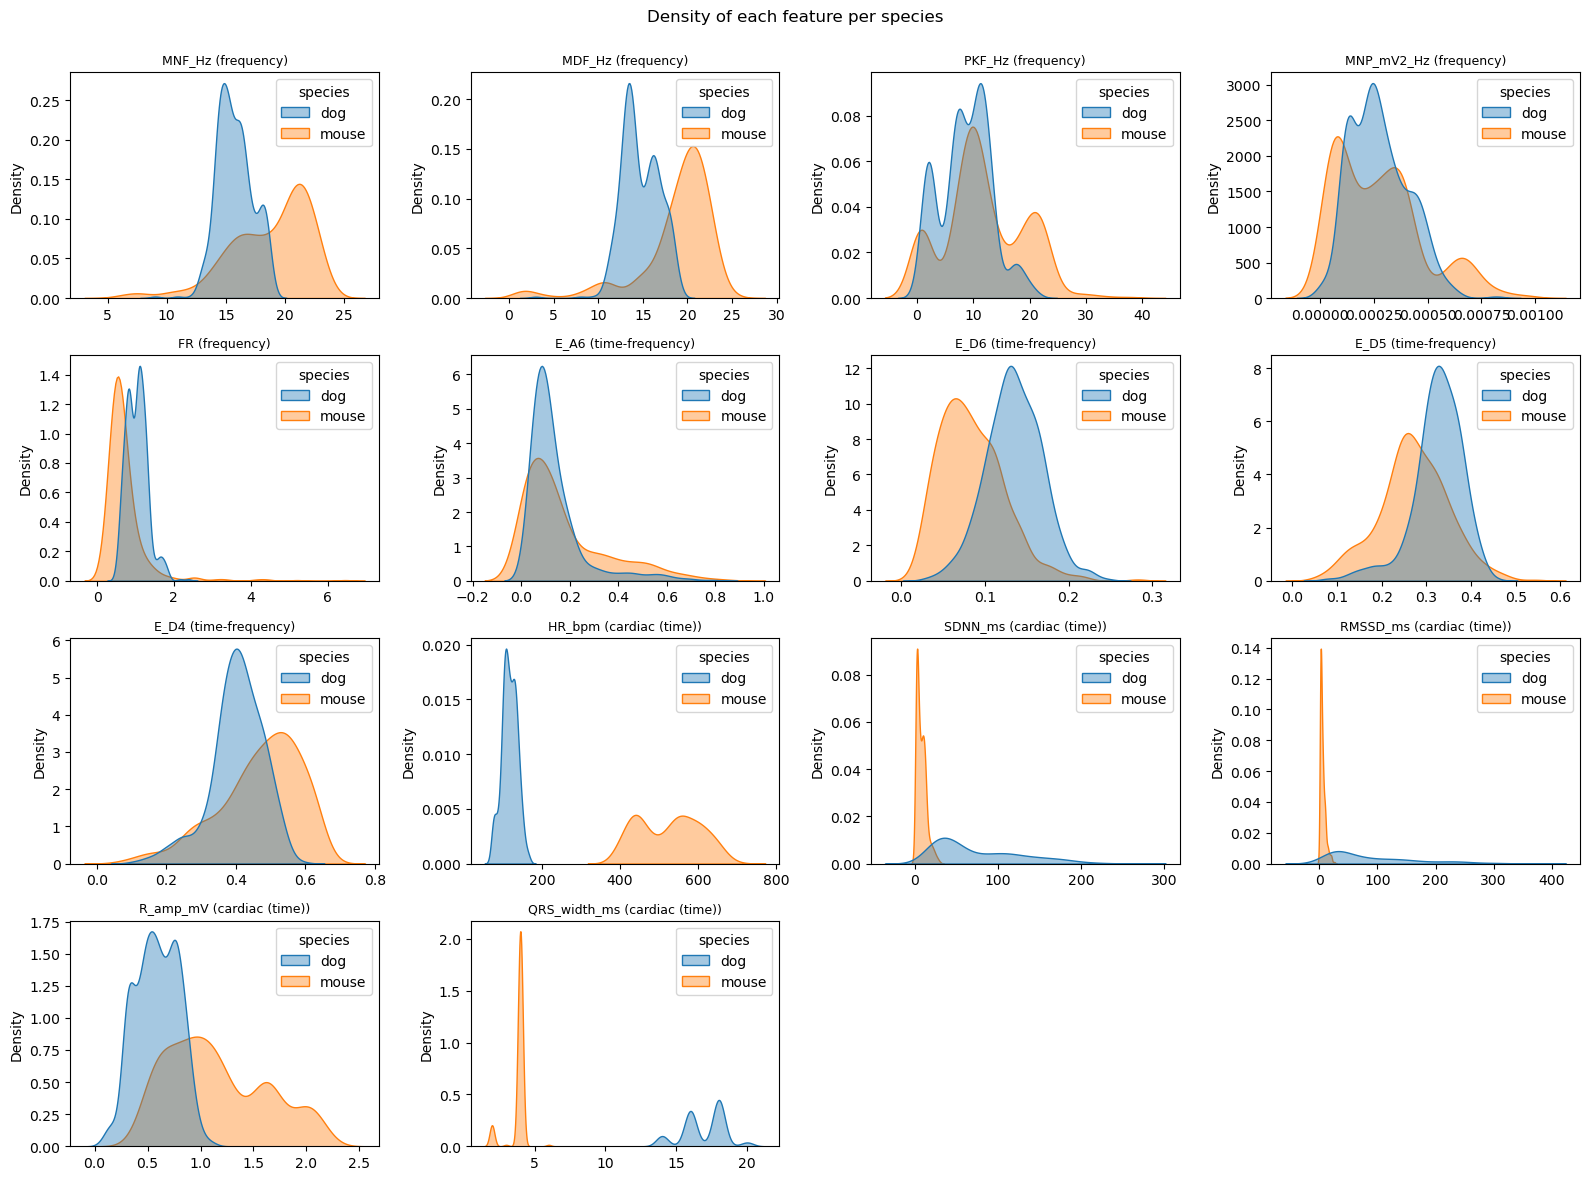

In [127]:
# Distribution of each feature per species (density curves)
n_cols = 4
n_rows = int(np.ceil(len(feature_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3 * n_rows))
axes = axes.ravel()
for ax, feature in zip(axes, feature_names):
    sns.kdeplot(data=features, x=feature, hue="species", palette=SPECIES_COLORS,
                fill=True, common_norm=False, alpha=0.4, ax=ax)
    ax.set_title(f"{feature} ({feature_domain[feature]})", fontsize=9)
    ax.set_xlabel("")
for ax in axes[len(feature_names):]:
    ax.axis("off")
fig.suptitle("Density of each feature per species", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

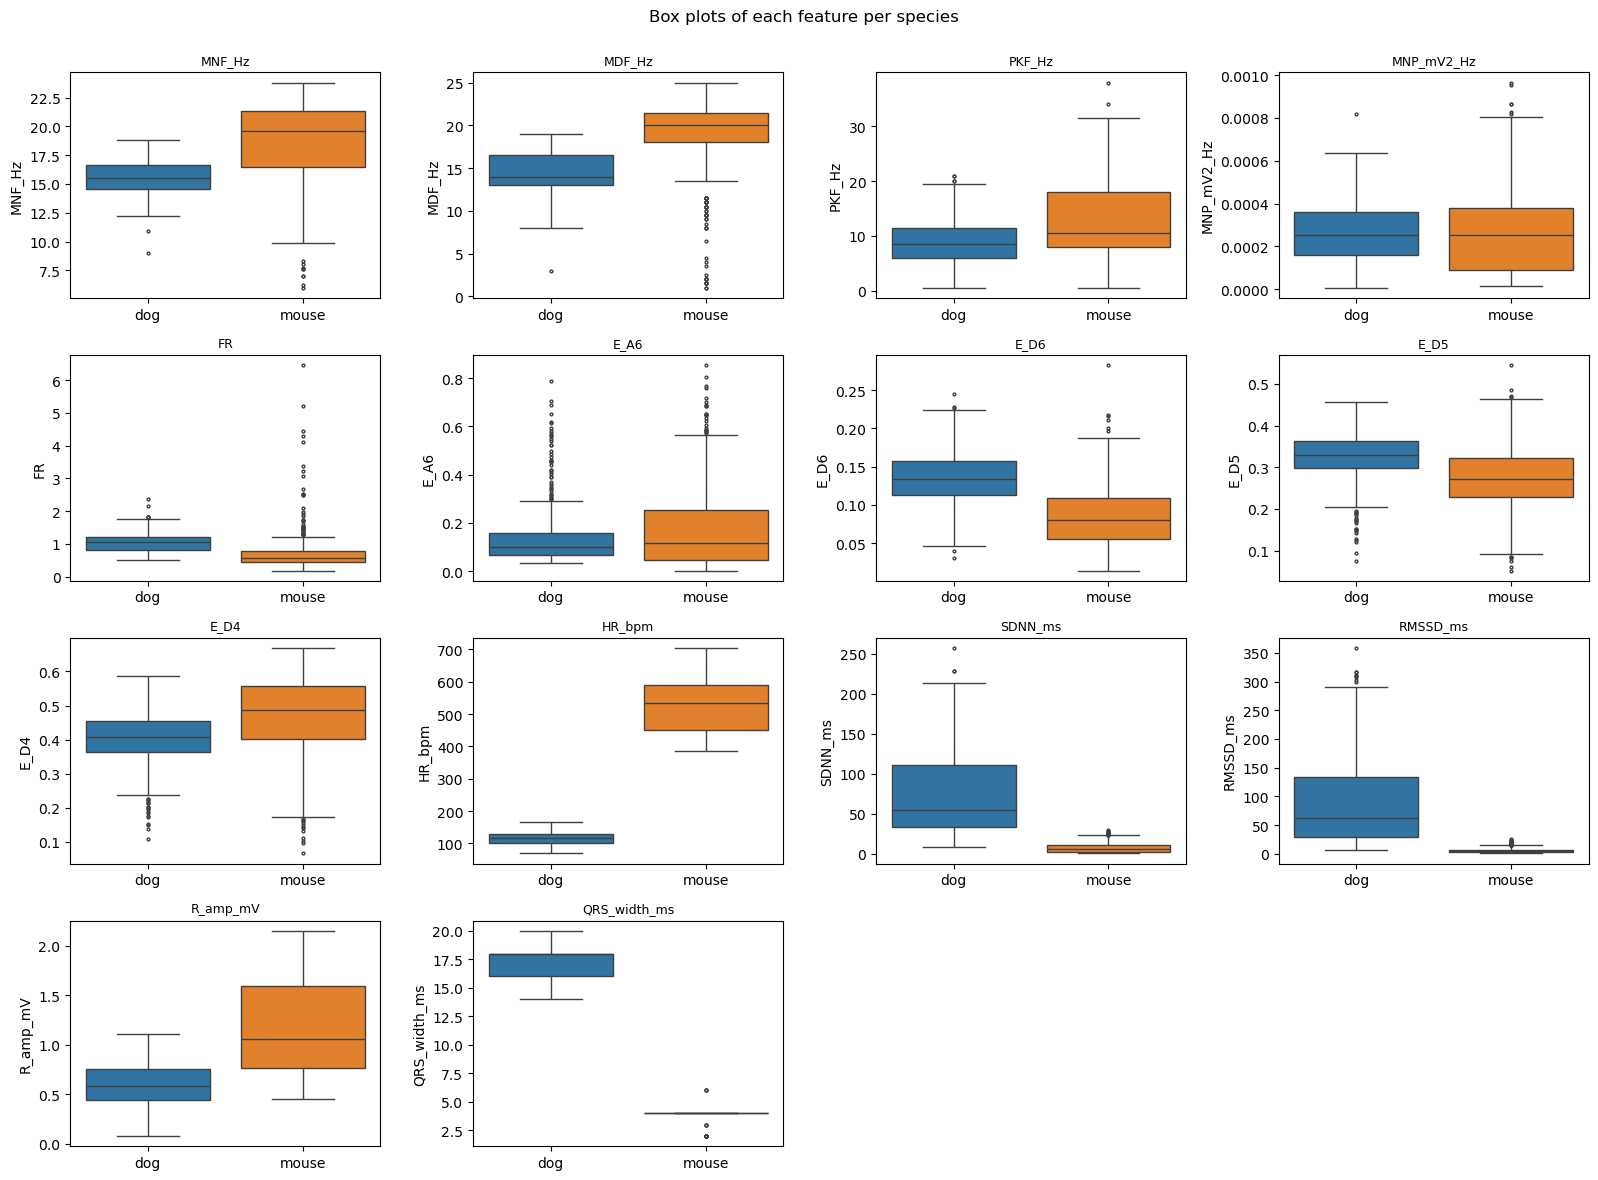

In [128]:
# Box plots per species
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3 * n_rows))
axes = axes.ravel()
for ax, feature in zip(axes, feature_names):
    sns.boxplot(data=features, x="species", y=feature, hue="species", palette=SPECIES_COLORS,
                legend=False, ax=ax, fliersize=2)
    ax.set_title(feature, fontsize=9)
    ax.set_xlabel("")
for ax in axes[len(feature_names):]:
    ax.axis("off")
fig.suptitle("Box plots of each feature per species", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

**Interpretation.** Cardiac features show almost no overlap between species: mice have a higher heart rate, a narrower QRS complex, and lower variability, while dogs show high SDNN and RMSSD due to their physiological respiratory sinus arrhythmia. In the frequency and time-frequency domains, mice shift toward higher frequencies (higher MNF, MDF, and E_D4; lower E_D6 and FR), but the distributions overlap considerably. PKF and MNP are bimodal in mice, and E_A6 is almost identical in both species. Mouse QRS width only takes values of 2, 4, or 6 ms because it is close to the 2-ms resolution. The extreme points in the box plots correspond to valid windows: in dogs they reflect physiological respiratory sinus arrhythmia, and in mice their bimodal spectrum.

In [129]:
ALPHA = 0.05
dog = features[features["species"] == "dog"]
mouse = features[features["species"] == "mouse"]

test_rows = []
for feature in feature_names:
    x_dog, x_mouse = dog[feature], mouse[feature]
    # Normality of each class (Shapiro-Wilk)
    p_norm_dog, p_norm_mouse = stats.shapiro(x_dog).pvalue, stats.shapiro(x_mouse).pvalue
    normal = (p_norm_dog >= ALPHA) and (p_norm_mouse >= ALPHA)
    # ANOVA if both classes are normal; otherwise Kruskal-Wallis
    if normal:
        test_name, p_value = "ANOVA", stats.f_oneway(x_dog, x_mouse).pvalue
    else:
        test_name, p_value = "Kruskal-Wallis", stats.kruskal(x_dog, x_mouse).pvalue
    # Fisher ratio for two classes: (mean difference)^2 / (sum of variances)
    fisher = (x_dog.mean() - x_mouse.mean()) ** 2 / (x_dog.var() + x_mouse.var())
    # AUC of the feature alone (values below 0.5 mean the feature is lower in mice)
    auc = roc_auc_score(features["label"], features[feature])
    test_rows.append({"feature": feature, "domain": feature_domain[feature],
                      "Shapiro p (dog)": p_norm_dog, "Shapiro p (mouse)": p_norm_mouse,
                      "test": test_name, "p-value": p_value, "significant": p_value < ALPHA,
                      "Fisher ratio": fisher, "AUC": max(auc, 1 - auc)})

test_table = pd.DataFrame(test_rows).set_index("feature").sort_values("Fisher ratio", ascending=False)
test_table.style.format({"Shapiro p (dog)": "{:.1e}", "Shapiro p (mouse)": "{:.1e}", "p-value": "{:.1e}",
                         "Fisher ratio": "{:.2f}", "AUC": "{:.3f}"})

,domain,Shapiro p (dog),Shapiro p (mouse),test,p-value,significant,Fisher ratio,AUC
feature,,,,,,,,
QRS_width_ms,cardiac (time),2.8e-22,7.9e-38,Kruskal-Wallis,2.6e-180,True,68.18,1.000
HR_bpm,cardiac (time),1.0e-02,6.3e-11,Kruskal-Wallis,2.2e-160,True,25.49,1.000
SDNN_ms,cardiac (time),1.4e-17,6.5e-18,Kruskal-Wallis,3.1e-155,True,1.68,0.992
R_amp_mV,cardiac (time),9.2e-06,2.1e-13,Kruskal-Wallis,4.7e-90,True,1.25,0.873
RMSSD_ms,cardiac (time),3.8e-20,3.0e-22,Kruskal-Wallis,2.5e-155,True,1.23,0.992
E_D6,time-frequency,6.2e-01,3.2e-11,Kruskal-Wallis,2.7e-77,True,0.98,0.845
MDF_Hz,frequency,2.8e-11,2.6e-25,Kruskal-Wallis,8.9e-84,True,0.70,0.859
MNF_Hz,frequency,7.9e-08,1.9e-15,Kruskal-Wallis,1.5e-57,True,0.63,0.796
E_D5,time-frequency,1.3e-13,8.2e-02,Kruskal-Wallis,1.8e-35,True,0.31,0.730


**Interpretation.** No feature was normally distributed in both species, so all were compared with the Kruskal-Wallis test. Thirteen of the 14 features were significant; only E_A6 was not. With 972 windows, however, even small differences become significant: MNP has p = 0.013, but its Fisher ratio (0.00) and AUC (0.55) show that it does not separate the species. For this reason, the Fisher ratio and AUC are better indicators than the p-value. QRS width and HR reach AUC = 1.00, while the best non-cardiac features are E_D6 (0.85) and MDF (0.86).

In [130]:
# Same comparison at the animal level: one mean value per animal (17 dogs vs. 8 mice),
# which avoids treating windows of the same animal as independent observations
animal_means = features.groupby(["record_id", "species"], observed=True)[feature_names].mean().reset_index()
animal_tests = pd.DataFrame({
    feature: {"p-value (animal level)": stats.kruskal(
        animal_means.loc[animal_means["species"] == "dog", feature],
        animal_means.loc[animal_means["species"] == "mouse", feature]).pvalue}
    for feature in feature_names}).T
animal_tests["significant"] = animal_tests["p-value (animal level)"] < ALPHA
animal_tests.loc[test_table.index].style.format({"p-value (animal level)": "{:.1e}"})

,p-value (animal level),significant
feature,,
QRS_width_ms,6.0e-05,True
HR_bpm,7.5e-05,True
SDNN_ms,7.5e-05,True
R_amp_mV,1.7e-03,True
RMSSD_ms,7.5e-05,True
E_D6,1.9e-04,True
MDF_Hz,3.0e-03,True
MNF_Hz,1.4e-02,True
E_D5,2.0e-02,True


**Interpretation.** Using one mean value per animal, 11 features remain significant, while PKF, E_A6, and MNP no longer are. This confirms that their window-level differences do not reflect a real difference between species. The p-values are larger than at the window level because there are only 17 dogs and 8 mice.

In [131]:
# Multivariate Fisher criterion (as in the course notebook) computed per domain: J = trace(W^-1 B)
# on standardized features, where W is the within-class scatter and B the between-class scatter
Z = StandardScaler().fit_transform(features[feature_names])
Z = pd.DataFrame(Z, columns=feature_names)


def fisher_criterion(Zd, labels):
    overall_mean = Zd.mean(axis=0)
    W = np.zeros((Zd.shape[1], Zd.shape[1]))
    B = np.zeros_like(W)
    for label in np.unique(labels):
        Zc = Zd[labels == label]
        mean_c = Zc.mean(axis=0)
        W += (Zc - mean_c).T @ (Zc - mean_c)                                   # within-class scatter
        B += len(Zc) * np.outer(mean_c - overall_mean, mean_c - overall_mean)  # between-class scatter
    return np.trace(np.linalg.pinv(W) @ B)


labels = features["label"].to_numpy()
domains = {d: [f for f in feature_names if feature_domain[f] == d] for d in dict.fromkeys(feature_domain.values())}
domains["all features"] = feature_names
domain_fisher = pd.Series({d: fisher_criterion(Z[cols].to_numpy(), labels) for d, cols in domains.items()},
                          name="Fisher criterion J")
display(domain_fisher.round(3).to_frame())

# Feature rankings with ReliefF and mRMR (as in the course notebook)
relief = ReliefF(n_neighbors=10, n_features_to_select=len(feature_names)).fit(Z.to_numpy(), labels)
relief_scores = pd.Series(relief.feature_importances_, index=feature_names, name="ReliefF")
mrmr_order = mrmr_classif(X=Z, y=features["label"], K=len(feature_names), show_progress=False)
mrmr_rank = pd.Series(range(1, len(mrmr_order) + 1), index=mrmr_order, name="mRMR rank")

ranking = pd.concat([test_table[["domain", "Fisher ratio", "AUC"]], relief_scores, mrmr_rank], axis=1)
ranking.sort_values("Fisher ratio", ascending=False).round(3)

,Fisher criterion J
frequency,0.615
time-frequency,1.071
cardiac (time),67.920
all features,110.799


,domain,Fisher ratio,AUC,ReliefF,mRMR rank
QRS_width_ms,cardiac (time),68.181,1.000,0.700,1
HR_bpm,cardiac (time),25.489,1.000,0.575,2
SDNN_ms,cardiac (time),1.681,0.992,0.152,3
R_amp_mV,cardiac (time),1.254,0.873,0.174,4
RMSSD_ms,cardiac (time),1.226,0.992,0.126,5
E_D6,time-frequency,0.981,0.845,0.043,6
MDF_Hz,frequency,0.705,0.859,0.072,7
MNF_Hz,frequency,0.633,0.796,0.069,8
E_D5,time-frequency,0.309,0.730,0.032,9
FR,frequency,0.221,0.835,0.024,11


**Interpretation.** The cardiac domain shows the highest separability (J = 67.9), far above the time-frequency (1.07) and frequency (0.62) domains. Combining all features increases J to 110.8, suggesting that the domains provide complementary information. ReliefF and mRMR agree in ranking QRS width and HR first, followed by the remaining cardiac features, E_D6, and MDF. The only discrepancy is MNP: ReliefF gives it a relatively high score despite a null Fisher ratio, probably because it captures the bimodal shape of its distribution in mice rather than a difference in means.

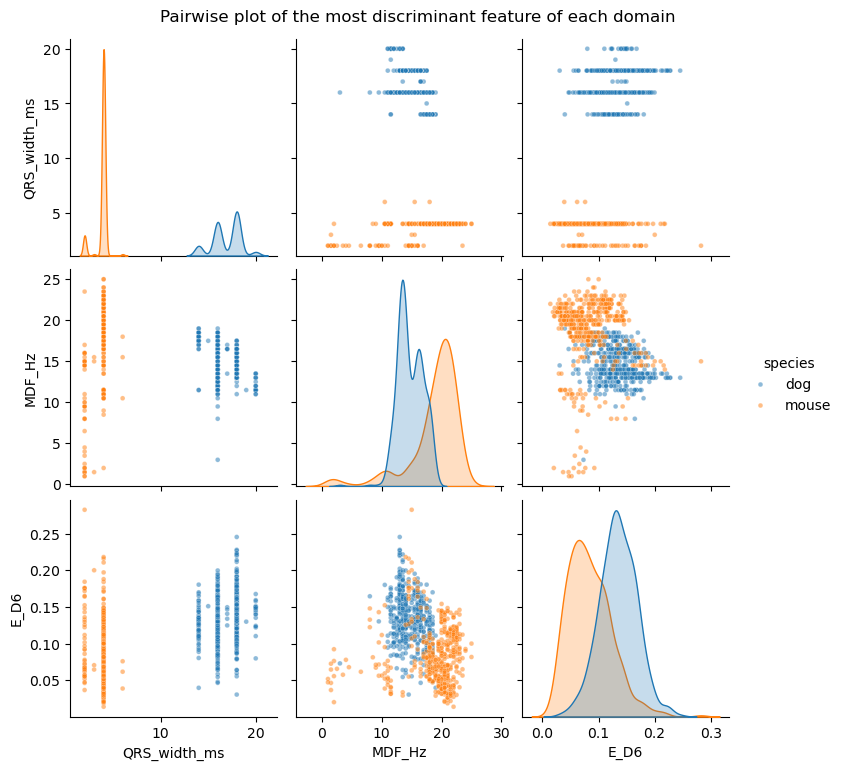

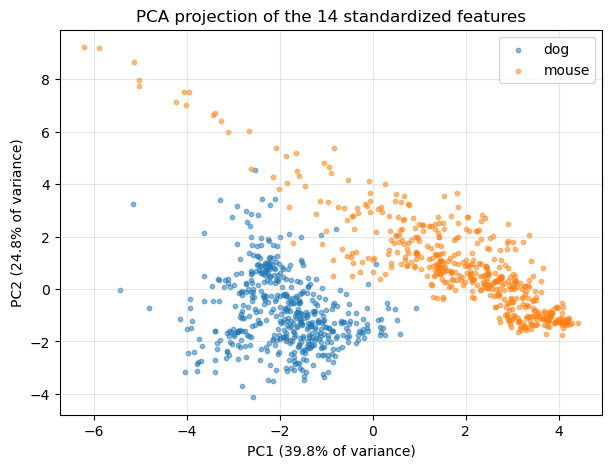

In [132]:
# Visual separability: pairwise plot of the most discriminant feature of each domain and PCA projection
top_by_domain = test_table.reset_index().groupby("domain").first()["feature"].tolist()
sns.pairplot(features[top_by_domain + ["species"]], hue="species", palette=SPECIES_COLORS,
             diag_kind="kde", plot_kws={"s": 12, "alpha": 0.5})
plt.suptitle("Pairwise plot of the most discriminant feature of each domain", y=1.02)
plt.show()

pca = PCA(n_components=2).fit(Z)
pcs = pca.transform(Z)
fig, ax = plt.subplots(figsize=(7, 5))
for label, species in enumerate(SPECIES):
    m = features["label"] == label
    ax.scatter(pcs[m, 0], pcs[m, 1], s=10, alpha=0.5, color=SPECIES_COLORS[species], label=species)
ax.set(xlabel=f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}% of variance)",
       ylabel=f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}% of variance)",
       title="PCA projection of the 14 standardized features")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Interpretation.** In the pairwise plot, QRS width alone separates the species completely, whereas MDF and E_D6 overlap individually but partially separate the species when combined. In the PCA, the first two components explain 64.6% of the variance, and the species separate along PC1 with little overlap. The tail of mouse windows with high PC2 corresponds to windows with low MDF.

**Section summary.** Dogs and mice are clearly separable. Cardiac features are the most discriminant, while frequency and time-frequency features show consistent but more overlapping differences. Part of this separation comes from evident physiological differences such as heart rate, and the mouse QRS width is limited by the sampling resolution. For this reason, Section 5 evaluates whether each domain can classify the species on its own.

# 5. Data separability

This section evaluates whether the features allow each window to be automatically classified as dog or mouse. Five feature sets are compared: each domain separately, all features together, and the combination of frequency and time-frequency features. The latter excludes cardiac features to test whether separation depends only on evident differences such as heart rate. Each set is evaluated with a linear classifier (logistic regression) and a non-linear one (random forest).

Since windows from the same animal resemble each other, cross-validation is grouped by animal, so each model is always evaluated on animals it did not see during training. Four folds are used because there are only eight mice. Performance is measured with the metrics seen in class (accuracy, sensitivity, specificity, PPV, NPV, F1, and AUC), taking the mouse as the positive class.

In [133]:
# Feature sets to compare: each domain alone, frequency + time-frequency (no cardiac), and all features
feature_sets = {
    "frequency": domains["frequency"],
    "time-frequency": domains["time-frequency"],
    "cardiac (time)": domains["cardiac (time)"],
    "frequency + time-frequency": domains["frequency"] + domains["time-frequency"],
    "all features": feature_names,
}

# Classifiers (scaling inside the pipeline so it is fitted only on the training folds)
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, random_state=42)),
}

# Cross-validation grouped by animal: all windows of one animal fall in the same fold
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
y = features["label"].to_numpy()
groups = features["record_id"].to_numpy()


def classification_metrics(y_true, y_pred, y_score):
    # Metrics as in the course notebook (positive class = mouse)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Sensitivity": recall_score(y_true, y_pred),
            "Specificity": tn / (tn + fp),
            "PPV": precision_score(y_true, y_pred, zero_division=0),
            "NPV": tn / (tn + fn) if (tn + fn) > 0 else np.nan,
            "F1": f1_score(y_true, y_pred),
            "AUC": roc_auc_score(y_true, y_score)}


results, predictions = [], {}
for set_name, cols in feature_sets.items():
    X = features[cols].to_numpy()
    for model_name, model in models.items():
        y_score = cross_val_predict(model, X, y, groups=groups, cv=cv, method="predict_proba")[:, 1]
        y_pred = (y_score >= 0.5).astype(int)
        predictions[(set_name, model_name)] = (y_pred, y_score)
        results.append({"feature set": set_name, "model": model_name, "n features": len(cols),
                        **classification_metrics(y, y_pred, y_score)})

results_table = pd.DataFrame(results).set_index(["feature set", "model"])
results_table.style.format("{:.3f}", subset=results_table.columns[1:]).background_gradient(
    cmap="Greens", subset=["Accuracy", "F1", "AUC"])

**Interpretation.** With cardiac features, alone or combined with the others, both classifiers separate the species perfectly. This is expected because heart rate and QRS width barely overlap. Without cardiac features, performance decreases but remains high. The best result is obtained by the random forest with frequency and time-frequency features (accuracy of 0.853 and AUC of 0.930). In the frequency domain, the random forest clearly outperforms logistic regression (AUC of 0.895 vs. 0.681), possibly because the bimodal distributions of PKF and MNP in mice cannot be separated by a linear boundary. In the time-frequency domain, in contrast, both models perform almost equally, which suggests that the difference in energy distribution is mostly linear.

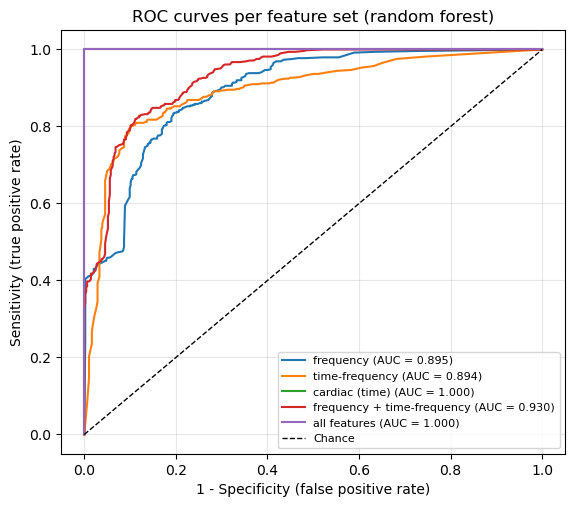

In [134]:
# ROC curves of each feature set (random forest)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for set_name in feature_sets:
    _, y_score = predictions[(set_name, "Random forest")]
    fpr, tpr, _ = roc_curve(y, y_score)
    ax.plot(fpr, tpr, label=f"{set_name} (AUC = {roc_auc_score(y, y_score):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set(xlabel="1 - Specificity (false positive rate)", ylabel="Sensitivity (true positive rate)",
       title="ROC curves per feature set (random forest)")
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3)
plt.show()

**Interpretation.** ROC curves show performance across all possible decision thresholds, not only at 0.5. With cardiac features, the curve reaches the upper-left corner (AUC = 1.000), meaning there is a threshold that separates both species without errors. Without them, the frequency and time-frequency domains have almost the same AUC (0.895 and 0.894), but their curves have different shapes:

- Time-frequency features perform better when few false positives are required. At a false positive rate of 0.05, they detect about 70% of mice, compared with less than 50% for frequency features.
- Frequency features perform better when high sensitivity is required.

This indicates that both domains provide complementary information, which explains why combining them raises the AUC to 0.930.

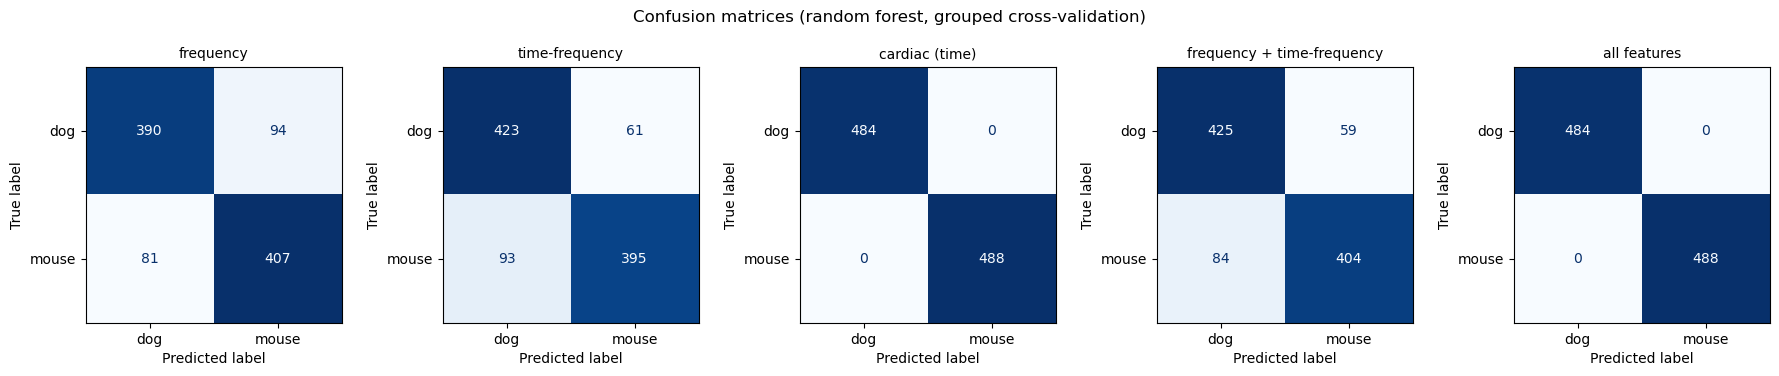

In [135]:
# Confusion matrices of each feature set (random forest)
fig, axes = plt.subplots(1, len(feature_sets), figsize=(18, 3.6))
for ax, set_name in zip(axes, feature_sets):
    y_pred, _ = predictions[(set_name, "Random forest")]
    ConfusionMatrixDisplay(confusion_matrix(y, y_pred), display_labels=SPECIES).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(set_name, fontsize=10)
fig.suptitle("Confusion matrices (random forest, grouped cross-validation)", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Interpretation.** The confusion matrices show the direction of the errors:

- **Frequency:** errors are similarly distributed between species (94 dogs classified as mice and 81 mice as dogs), so this domain does not favor either class.
- **Time-frequency:** errors lean toward mice (93 vs. 61). This suggests that some mice have an energy distribution similar to that of dogs, possibly the windows with more low-frequency energy observed in Section 4.
- **Frequency and time-frequency combined:** total errors decrease from 175 and 154 to 143. Almost all of the improvement occurs in dogs (from 94 to 59 compared with frequency features alone), while misclassified mice remain close to 84. Therefore, the remaining errors mainly correspond to mice that resemble dogs in both domains.

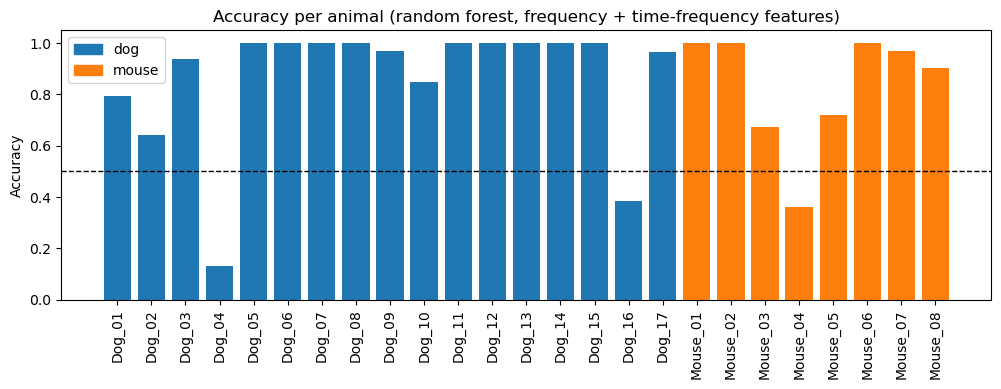

In [136]:
# Accuracy per animal without cardiac features: which animals are harder to classify?
y_pred, _ = predictions[("frequency + time-frequency", "Random forest")]
per_animal = (features.assign(correct=(y_pred == y))
              .groupby(["species", "record_id"], observed=True)["correct"].mean()
              .rename("accuracy").reset_index())

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(per_animal["record_id"], per_animal["accuracy"],
       color=per_animal["species"].map(SPECIES_COLORS))
ax.axhline(0.5, color="k", ls="--", lw=1)
ax.set(ylabel="Accuracy", ylim=(0, 1.05),
       title="Accuracy per animal (random forest, frequency + time-frequency features)")
ax.tick_params(axis="x", rotation=90)
ax.legend(handles=[Patch(color=c, label=s) for s, c in SPECIES_COLORS.items()])
plt.show()

**Interpretation.** Errors do not occur randomly across windows but are concentrated in a few animals:

- 16 of the 25 animals exceed an accuracy of 0.9, and 12 of them are classified almost without errors.
- Dog_04 (0.13), Dog_16 (0.38), and Mouse_04 (0.36) fall below chance, meaning the model assigns most of their windows to the other species.

This indicates that the ECG of these animals consistently differs from the rest of their species, either due to individual characteristics or recording conditions. It also explains the confusion matrices: Mouse_04, Mouse_03, and Mouse_05 account for about 75 of the 84 misclassified mice.

Since the real unit of generalization is the animal rather than the window, a few atypical animals strongly affect the final performance. This is especially true for mice, where each animal represents one-eighth of the class.

**Section summary.** The classification results confirm the separability order observed in Section 4. Cardiac features distinguish both species without errors, which was expected given their marked physiological differences. More importantly, without them, the morphology and spectral content of the ECG still correctly classify about 85% of the windows (AUC = 0.930), because the frequency and time-frequency domains complement each other. The remaining error does not come from isolated windows but from a few atypical animals. For this reason, with only eight mice, these results should be confirmed with a larger number of animals before being generalized.

# AI Use Declaration

Claude (Anthropic), was used as an assistant throughout this laboratory. It was used to:

- Propose and debug the code for data handling, feature extraction, statistical analysis, and classification.
- Improve the wording of texts written by the author in Spanish and translate them into English.

Methodological decisions were discussed with the model and adjusted according to the professor's recommendations, including the choice of species as classes and of the feature domains. The author ran all cells, verified the outputs, and reviewed each interpretation before including it. She also corrected the errors detected in the code and texts. The author takes responsibility for the final content.

# References

Behar, J. A., Rosenberg, A. A., Weiser-Bitoun, I., Shemla, O., Alexandrovich, A., Konyukhov, E., & Yaniv, Y. (2018). PhysioZoo: A novel open access platform for heart rate variability analysis of mammalian electrocardiographic data. *Frontiers in Physiology, 9*, 1390. https://doi.org/10.3389/fphys.2018.01390

Breeding-Allison, J., & Walleser, E. (2026). *Enhancing AI-based ECG delineation with deep learning denoising techniques* [Preprint]. arXiv. https://doi.org/10.48550/arXiv.2605.03183

Dourson, A., Santilli, R., Marchesotti, F., Schneiderman, J., Stiel, O. R., Junior, F., Fitzke, M., Sithirangathan, N., Walleser, E., Qiao, X., & Parkinson, M. (2023). *PulseNet: Deep learning ECG-signal classification using random augmentation policy and continous wavelet transform for canines* [Preprint]. arXiv. https://doi.org/10.48550/arXiv.2305.15424

Flanders, W. H., Moïse, N. S., Santilli, R., Basran, P. S., Pariaut, R., & Perego, M. (2025). Machine learning differentiates right posterior from right anterior accessory pathways using 6-lead electrocardiograms in dogs with ventricular preexcitation. *Journal of the American Veterinary Medical Association, 264*(5), 1–9. https://doi.org/10.2460/javma.25.07.0453

Hellemans, A., Schittekatte, M., Covents, M., & Smets, P. (2022). Diagnosis and management of arrhythmias in dogs: A cross-sectional online survey among Flemish veterinary practitioners. *Veterinary Record Open, 9*(1), e35. https://doi.org/10.1002/vro2.35

Hertzer, J., Gordon, S., & Wesselowski, S. (2022). Effects of recording device, body position, electrode placement, and sedation on electrocardiogram intervals in dogs. *The Veterinary Journal, 288*, 105885. https://doi.org/10.1016/j.tvjl.2022.105885

Monachino, G., Zanchi, B., Fiorillo, L., Conte, G., Auricchio, A., Tzovara, A., & Faraci, F. D. (2023). Deep generative models: The winning key for large and easily accessible ECG datasets? *Computers in Biology and Medicine, 167*, 107655. https://doi.org/10.1016/j.compbiomed.2023.107655

Moody, G. B., & Mark, R. G. (2001). The impact of the MIT-BIH Arrhythmia Database. *IEEE Engineering in Medicine and Biology Magazine, 20*(3), 45–50. https://doi.org/10.1109/51.932724

Mukherjee, J., Mohapatra, S. S., Jana, S., Das, P. K., Ghosh, P. R., Das, K., & Banerjee, D. (2020). A study on the electrocardiography in dogs: Reference values and their comparison among breeds, sex, and age groups. *Veterinary World, 13*(10), 2216–2220. https://doi.org/10.14202/vetworld.2020.2216-2220

Pollard, T., Moody, B. E., Lehman, L., Gow, B., Fernandes, C., Xie, C., Johnson, A., Mark, R. G., & Heldt, T. (2026). PhysioNet as a global platform for biomedical research. *Nature Health*. https://doi.org/10.1038/s44360-026-00096-z

Romito, G., Castagna, P., Pelle, N. G., Testa, F., Sabetti, M. C., & Cipone, M. (2022). The canine T wave: A retrospective analysis on qualitative and quantitative T wave variables obtained in 129 healthy dogs and proposed reference intervals. *Journal of Veterinary Cardiology, 42*, 52–64. https://doi.org/10.1016/j.jvc.2022.06.003

Santilli, R., Moïse, N. S., Pariaut, R., & Perego, M. (2018). *Electrocardiography of the dog and cat: Diagnosis of arrhythmias* (2nd ed.). Edra.

Shemla, O., & Behar, J. (2019). *PhysioZoo – mammalian NSR databases* (Version 1.0.0) [Data set]. PhysioNet. https://doi.org/10.13026/p63q-hq95

Wagner, P., Strodthoff, N., Bousseljot, R.-D., Kreiseler, D., Lunze, F. I., Samek, W., & Schaeffter, T. (2020). PTB-XL, a large publicly available electrocardiography dataset. *Scientific Data, 7*, 154. https://doi.org/10.1038/s41597-020-0495-6

Zanchi, B., Monachino, G., Fiorillo, L., Conte, G., Auricchio, A., Tzovara, A., & Faraci, F. D. (2025). Synthetic ECG signals generation: A scoping review. *Computers in Biology and Medicine, 184*, 109453. https://doi.org/10.1016/j.compbiomed.2024.109453